In [1]:
# ============================================================
# 0. PREPARACIÓN DEL ENTORNO
# ============================================================
# Importamos las librerías necesarias para procesar los datos.
# ============================================================

import pandas as pd
import numpy as np
import os
from collections import deque

In [2]:
# Usamos directamente el CSV ya extraído, en la misma carpeta del notebook.
ruta_csv = "2019-Nov-enriquecido.csv"

# Carpeta para las salidas intermedias de cada etapa.
os.makedirs("salidas", exist_ok=True)

print("Dataset disponible:", os.path.exists(ruta_csv))

Dataset disponible: True


In [3]:
# ============================================================
# 0.1 CONFIGURACIÓN DEL PIPELINE
# ============================================================
# Definimos funciones y estructuras auxiliares para las
# distintas etapas del procesamiento.
# ============================================================

import heapq
import time
from collections import OrderedDict
from scipy.sparse import csr_matrix

TAMANO_LOTE = 10_000
VENTANA_ESTRUCTURAS = 10_000


def busqueda_binaria(lista, objetivo):
    izquierda = 0
    derecha = len(lista) - 1

    while izquierda <= derecha:
        medio = (izquierda + derecha) // 2

        if lista[medio] == objetivo:
            return medio
        elif lista[medio] < objetivo:
            izquierda = medio + 1
        else:
            derecha = medio - 1

    return -1


class CacheLRU:
    def __init__(self, capacidad):
        self.capacidad = capacidad
        self.cache = OrderedDict()

    def obtener(self, clave):
        if clave not in self.cache:
            return None
        self.cache.move_to_end(clave)
        return self.cache[clave]

    def guardar(self, clave, valor):
        if clave in self.cache:
            self.cache.move_to_end(clave)
        self.cache[clave] = valor

        if len(self.cache) > self.capacidad:
            self.cache.popitem(last=False)


print("Configuración del pipeline lista.")
print("Tamaño de lote:", TAMANO_LOTE)


Configuración del pipeline lista.
Tamaño de lote: 10000


## ETAPA 0 — INGESTA Y BUFFER

**Objetivo:** recibir los eventos en orden de llegada y entregarlos a la Etapa 1 sin cargar toda la base en memoria.

**Todo el stream pasa por una cola FIFO** (`deque`, encolar y desencolar en O(1)) con capacidad máxima de 2 lotes. El CSV se lee por bloques, cada evento **entra por atrás** de la cola y, cuando la cola se llena, la Etapa 1 **saca por adelante** un lote de 10,000 eventos. Así la memoria depende del tamaño del buffer, no del tamaño del stream.

In [4]:
# El stream pasa por una cola FIFO con capacidad máxima antes de llegar a la Etapa 1.
CAPACIDAD_BUFFER = 2 * TAMANO_LOTE


def stream_por_buffer(ruta):
    """Lee el CSV por bloques, encola cada evento y entrega lotes en orden de llegada."""
    buffer = deque()

    for bloque in pd.read_csv(ruta, chunksize=TAMANO_LOTE):
        columnas = bloque.columns

        for evento in bloque.itertuples(index=False, name=None):
            buffer.append(evento)                       # entra por atrás

            if len(buffer) == CAPACIDAD_BUFFER:         # buffer lleno: sale un lote por adelante
                yield pd.DataFrame([buffer.popleft() for _ in range(TAMANO_LOTE)], columns=columnas)

    while buffer:                                       # lo que queda al terminar el stream
        yield pd.DataFrame([buffer.popleft() for _ in range(min(TAMANO_LOTE, len(buffer)))], columns=columnas)


# Recorremos todo el stream a través del buffer y comprobamos el orden de salida.
inicio = time.perf_counter()

total_eventos = 0
total_lotes = 0
tipos_evento = pd.Series(dtype="int64")
ultimo_id = 0
fifo_correcto = True

for lote in stream_por_buffer(ruta_csv):
    total_lotes += 1
    total_eventos += len(lote)
    tipos_evento = tipos_evento.add(
        lote["event_type"].value_counts(),
        fill_value=0
    )

    # FIFO: los event_id (orden de llegada) deben salir siempre en orden creciente.
    fifo_correcto &= lote["event_id"].is_monotonic_increasing and lote["event_id"].iloc[0] > ultimo_id
    ultimo_id = lote["event_id"].iloc[-1]

tiempo_etapa0 = time.perf_counter() - inicio

print("Lotes entregados por el buffer:", total_lotes)
print("Eventos que pasaron por la cola:", f"{total_eventos:,}")
print("Capacidad máxima del buffer:", f"{CAPACIDAD_BUFFER:,}", "eventos")
print("Tiempo Etapa 0:", round(tiempo_etapa0, 2), "segundos")

Lotes entregados por el buffer: 1010
Eventos que pasaron por la cola: 10,099,764
Capacidad máxima del buffer: 20,000 eventos
Tiempo Etapa 0: 51.96 segundos


In [5]:
# Revisamos la distribución de eventos del universo completo (los tipos mal escritos se normalizan en la Etapa 1).
print("Tipos de evento:")
print(tipos_evento.astype(int).sort_values(ascending=False))


Tipos de evento:
event_type
view         9825809
purchase      148475
cart          122942
VIEW            2480
PURCHASE          32
CART              26
dtype: int64


In [6]:
# Validamos el comportamiento FIFO sobre todo el stream: el primero en entrar es el primero en salir.
print("FIFO correcto en los", f"{total_eventos:,}", "eventos:", fifo_correcto)

FIFO correcto en los 10,099,764 eventos: True


In [7]:
# La Etapa 1 recibe sus lotes desde el buffer: stream_por_buffer(ruta_etapa1_entrada).
ruta_etapa1_entrada = ruta_csv

print("Universo enviado a Etapa 1:", f"{total_eventos:,}", "eventos")

Universo enviado a Etapa 1: 10,099,764 eventos


## ETAPA 1 — PREPROCESAMIENTO POR LOTES

**Objetivo:** limpiar registros inválidos o duplicados, convertir fechas y preparar los eventos para las siguientes etapas.

Los lotes llegan desde el buffer FIFO de la Etapa 0. La limpieza se hace **sin usar las columnas `is_invalid` ni `is_duplicate`** (son etiquetas para evaluar, no para decidir):

- **Validar:** fecha válida, tipo de evento conocido, `user_id` presente y precio ≥ 0. Lo recuperable se normaliza (`"VIEW "` → `view`).
- **Deduplicar:** se ordena el lote por la clave del evento (merge sort), así los repetidos quedan contiguos; los que cruzan de un lote a otro se detectan con **búsqueda binaria** sobre las claves ordenadas del lote anterior.

In [8]:
# Procesamos todo el universo: validar, normalizar y quitar duplicados.
ruta_etapa1 = "salidas/etapa1_limpia.csv"

if os.path.exists(ruta_etapa1):
    os.remove(ruta_etapa1)

TIPOS_VALIDOS = ["view", "cart", "purchase"]

inicio = time.perf_counter()

registros_originales = 0
registros_invalidos = 0
registros_duplicados = 0
registros_limpios = 0
nulos_total = None
muestra_etapa1 = None
claves_lote_anterior = []   # ordenadas, para la búsqueda binaria entre lotes
ids_invalidos, ids_duplicados = [], []   # solo para evaluar contra las etiquetas

for lote in stream_por_buffer(ruta_etapa1_entrada):   # lotes desde el buffer FIFO
    registros_originales += len(lote)

    nulos_lote = lote.isnull().sum()
    nulos_total = nulos_lote if nulos_total is None else nulos_total.add(nulos_lote, fill_value=0)

    # Normalizamos lo recuperable y validamos el resto.
    lote["event_type"] = lote["event_type"].str.strip().str.lower()
    lote["event_time"] = pd.to_datetime(lote["event_time"], errors="coerce", utc=True)

    valido = (
        lote["event_time"].notna() &
        lote["event_type"].isin(TIPOS_VALIDOS) &
        lote["user_id"].notna() &
        (lote["price"] >= 0)
    )
    registros_invalidos += (~valido).sum()
    ids_invalidos += lote.loc[~valido, "event_id"].tolist()
    limpio = lote[valido].copy()

    # Clave del evento (no event_id: una copia reenviada recibe otro id).
    # user_id como entero: si un lote trae nulos pandas lo lee como float (5604.0) y la clave cambiaría entre lotes.
    limpio["clave"] = (
        limpio["event_time"].astype(str) + "|" + limpio["event_type"] + "|" +
        limpio["product_id"].astype(str) + "|" + limpio["price"].astype(str) + "|" +
        limpio["user_id"].astype("int64").astype(str) + "|" + limpio["user_session"].astype(str)
    )

    # Ordenamos por clave: los duplicados del lote quedan contiguos.
    limpio = limpio.sort_values("clave", kind="mergesort")
    repetido = limpio["clave"].eq(limpio["clave"].shift())   # igual al anterior = repetido

    # Duplicados entre lotes: búsqueda binaria en las claves del lote anterior.
    repetido |= limpio["clave"].map(lambda c: busqueda_binaria(claves_lote_anterior, c) != -1)

    registros_duplicados += repetido.sum()
    ids_duplicados += limpio.loc[repetido, "event_id"].tolist()
    limpio = limpio[~repetido]
    claves_lote_anterior = limpio["clave"].tolist()

    limpio = limpio.drop(columns="clave").sort_values(["event_time", "event_id"])
    registros_limpios += len(limpio)

    limpio.to_csv(
        ruta_etapa1,
        mode="a",
        header=not os.path.exists(ruta_etapa1),
        index=False
    )

    if muestra_etapa1 is None:
        muestra_etapa1 = limpio.head(VENTANA_ESTRUCTURAS).copy()

tiempo_etapa1 = time.perf_counter() - inicio

print("Registros originales:", f"{registros_originales:,}")
print("Registros limpios:", f"{registros_limpios:,}")
print("Tiempo Etapa 1:", round(tiempo_etapa1, 2), "segundos")

Registros originales: 10,099,764
Registros limpios: 9,988,997
Tiempo Etapa 1: 210.08 segundos


In [9]:
# Revisamos los valores nulos encontrados en todo el universo.
print("Valores nulos por columna:")
print(nulos_total[nulos_total > 0].sort_values(ascending=False).astype(int))


Valores nulos por columna:
scheduled_time    10091052
order_id           9951257
order_type         9951257
search_query       9199105
category_code      3335762
brand              1424464
user_id               2458
dtype: int64


In [10]:
# Revisamos cuántos registros inválidos fueron descartados.
print("Registros inválidos descartados:", f"{registros_invalidos:,}")

Registros inválidos descartados: 7,356


In [11]:
# Comparamos registros originales y registros válidos.
registros_validos = registros_originales - registros_invalidos

print("Registros originales:", f"{registros_originales:,}")
print("Registros válidos:", f"{registros_validos:,}")


Registros originales: 10,099,764
Registros válidos: 10,092,408


In [12]:
# Revisamos cuántos duplicados fueron eliminados.
print("Duplicados eliminados:", f"{registros_duplicados:,}")

Duplicados eliminados: 103,411


In [13]:
# Comparamos con las etiquetas del dataset (solo para medir, no para decidir).
# - Inválidos no descartados: filas con event_type mal escrito que se repararon al normalizar.
# - Duplicados sin etiqueta: duplicados exactos que ya traía el dataset original.
etiquetas = pd.read_csv(ruta_csv, usecols=["event_id", "is_invalid", "is_duplicate"])

for nombre, detectados, columna in [("Inválidos", ids_invalidos, "is_invalid"),
                                    ("Duplicados", ids_duplicados, "is_duplicate")]:
    reales = set(etiquetas.loc[etiquetas[columna] == 1, "event_id"])
    detectados = set(detectados)
    print(f"{nombre:10} -> etiquetados: {len(reales):,} | detectados: {len(detectados):,} | "
          f"etiquetados encontrados: {len(reales & detectados):,} | detectados sin etiqueta: {len(detectados - reales):,}")

Inválidos  -> etiquetados: 9,895 | detectados: 7,356 | etiquetados encontrados: 7,356 | detectados sin etiqueta: 0
Duplicados -> etiquetados: 99,764 | detectados: 103,411 | etiquetados encontrados: 99,704 | detectados sin etiqueta: 3,707


In [14]:
# La salida ya quedó limpia de inválidos y duplicados.
print("Registros después de limpiar:", f"{registros_limpios:,}")


Registros después de limpiar: 9,988,997


In [15]:
# Confirmamos el formato de fecha usado para el análisis.
muestra_etapa1["event_time"] = pd.to_datetime(
    muestra_etapa1["event_time"],
    errors="coerce",
    utc=True
)

print("Tipo de event_time:", muestra_etapa1["event_time"].dtype)


Tipo de event_time: datetime64[ns, UTC]


In [16]:
# Revisamos una muestra ya ordenada cronológicamente.
muestra_etapa1[
    ["event_id", "event_time", "event_type"]
].head()


,event_id,event_time,event_type
0,1,2019-11-01 00:00:00+00:00,view
1,2,2019-11-01 00:00:00+00:00,view
2,3,2019-11-01 00:00:01+00:00,view
3,4,2019-11-01 00:00:01+00:00,view
4,5,2019-11-01 00:00:01+00:00,view


In [17]:
# La salida completa y limpia queda disponible para la Etapa 2.
ruta_etapa2_entrada = ruta_etapa1

print("Eventos enviados a Etapa 2:", f"{registros_limpios:,}")


Eventos enviados a Etapa 2: 9,988,997


## ETAPA 2 — COLA CON PRIORIDADES

**Objetivo:** atender las órdenes según su urgencia con un Heap.

En cada lote se calcula la prioridad de los eventos y **cada orden entra una sola vez al Heap** (una orden puede tener varias compras). Luego se despachan las órdenes más urgentes. El Heap vive durante todo el stream, así que recibe las compras de los 10 millones de eventos.

Prioridad (menor = más urgente): 1 alerta de fraude (la generará la Etapa 6) · 2 express · 3 estándar · 4 programada.

In [18]:
# Revisamos las variables que definen la prioridad en una muestra.
print("TIPOS DE EVENTO:")
print(muestra_etapa1["event_type"].value_counts(dropna=False))

print("\nTIPOS DE ORDEN:")
print(muestra_etapa1["order_type"].value_counts(dropna=False))


TIPOS DE EVENTO:
event_type
view        9694
purchase     100
cart          93
Name: count, dtype: int64

TIPOS DE ORDEN:
order_type
NaN          9787
express        54
standard       40
scheduled       6
Name: count, dtype: int64


### ETAPA 2.1 — Asignación de prioridad y construcción del Heap


In [19]:
# Asignamos prioridad por lotes; las compras entran al Heap y se despachan las más urgentes.
ruta_etapa2 = "salidas/etapa2_priorizada.csv"

if os.path.exists(ruta_etapa2):
    os.remove(ruta_etapa2)

DESPACHOS_POR_LOTE = 100   # órdenes que se atienden por cada lote que llega

inicio = time.perf_counter()
distribucion_prioridad = pd.Series(dtype="int64")
cola_prioridad = []        # el Heap vive durante todo el stream
ordenes_en_heap = set()    # una orden con varias compras entra una sola vez
ordenes_recibidas = 0
ordenes_despachadas = []
max_heap = 0

for lote in pd.read_csv(ruta_etapa2_entrada, chunksize=TAMANO_LOTE):
    condiciones = [
        lote["event_type"].eq("purchase") & lote["order_type"].eq("express"),
        lote["event_type"].eq("purchase") & lote["order_type"].eq("standard"),
        lote["event_type"].eq("purchase") & lote["order_type"].eq("scheduled"),
        lote["event_type"].eq("purchase"),
        lote["event_type"].eq("cart"),
        lote["event_type"].eq("view")
    ]

    valores = [2, 3, 4, 4, 5, 6]   # 1 = alertas de la Etapa 6
    lote["prioridad"] = np.select(condiciones, valores, default=7)

    distribucion_prioridad = distribucion_prioridad.add(
        lote["prioridad"].value_counts(),
        fill_value=0
    )

    # Cada orden entra al Heap: (prioridad, event_id para desempatar por llegada, orden, tipo de orden).
    compras = lote[lote["event_type"] == "purchase"].drop_duplicates("order_id")
    compras = compras[~compras["order_id"].isin(ordenes_en_heap)]
    ordenes_en_heap.update(compras["order_id"])

    for fila in compras.itertuples(index=False):
        heapq.heappush(cola_prioridad, (int(fila.prioridad), fila.event_id, fila.order_id, fila.order_type))
    ordenes_recibidas += len(compras)
    max_heap = max(max_heap, len(cola_prioridad))

    # Se atienden las órdenes más urgentes.
    for _ in range(min(DESPACHOS_POR_LOTE, len(cola_prioridad))):
        ordenes_despachadas.append(heapq.heappop(cola_prioridad))

    lote.to_csv(
        ruta_etapa2,
        mode="a",
        header=not os.path.exists(ruta_etapa2),
        index=False
    )

tiempo_etapa2 = time.perf_counter() - inicio

print("Eventos procesados:", f"{registros_limpios:,}")
print("Órdenes que entraron al Heap:", f"{ordenes_recibidas:,}")
print("Órdenes despachadas:", f"{len(ordenes_despachadas):,}")
print("Órdenes en espera al final:", f"{len(cola_prioridad):,}", "| tamaño máximo del Heap:", f"{max_heap:,}")
print("Tiempo Etapa 2:", round(tiempo_etapa2, 2), "segundos")

Eventos procesados: 9,988,997
Órdenes que entraron al Heap: 126,542
Órdenes despachadas: 99,853
Órdenes en espera al final: 26,689 | tamaño máximo del Heap: 26,789
Tiempo Etapa 2: 87.18 segundos


### ETAPA 2.2 — Validar que el Heap funciona


In [20]:
# Las primeras órdenes despachadas deben salir por urgencia, no por orden de llegada.
print("Primeras 10 órdenes despachadas:\n")

for prioridad, event_id, order_id, tipo_orden in ordenes_despachadas[:10]:
    print("Prioridad:", prioridad, "| ID:", event_id, "| Orden:", order_id, "|", tipo_orden)

# Sobre una copia (el Heap sigue vivo para las alertas de la Etapa 6):
# lo que queda sale ordenado por prioridad y, a igual prioridad, por llegada.
copia = cola_prioridad.copy()
resto = [heapq.heappop(copia)[:2] for _ in range(len(copia))]
print("\nEl resto del Heap sale ordenado por prioridad y llegada:", resto == sorted(resto))

Primeras 10 órdenes despachadas:

Prioridad: 2 | ID: 170 | Orden: ORD-00000002 | express
Prioridad: 2 | ID: 712 | Orden: ORD-00000003 | express
Prioridad: 2 | ID: 817 | Orden: ORD-00000004 | express
Prioridad: 2 | ID: 951 | Orden: ORD-00000006 | express
Prioridad: 2 | ID: 1581 | Orden: ORD-00000009 | express
Prioridad: 2 | ID: 1645 | Orden: ORD-00000011 | express
Prioridad: 2 | ID: 1754 | Orden: ORD-00000014 | express
Prioridad: 2 | ID: 1956 | Orden: ORD-00000016 | express
Prioridad: 2 | ID: 2028 | Orden: ORD-00000018 | express
Prioridad: 2 | ID: 2691 | Orden: ORD-00000021 | express

El resto del Heap sale ordenado por prioridad y llegada: True


### ETAPA 2.3 — Salida de la Etapa 2

In [21]:
# Revisamos la distribución de prioridad del universo completo.
print("Distribución por prioridad:")
print(distribucion_prioridad.sort_index().astype(int))

# La salida completa continúa hacia la Etapa 3.
ruta_etapa3_entrada = ruta_etapa2
print("Eventos enviados a Etapa 3:", f"{registros_limpios:,}")


Distribución por prioridad:
prioridad
2      91215
3      47139
4       8619
5     118298
6    9723726
dtype: int64
Eventos enviados a Etapa 3: 9,988,997


## ETAPA 3 — ALMACENAMIENTO, LOOKUP Y CACHÉ

**Objetivo:** consultar con baja latencia los datos de los **productos** (categoría, marca, precio y stock).

- **Tabla hash** (`dict`): clave = `product_id`. Funciona como un índice hash de base de datos: `tabla_productos[X]` equivale a `SELECT ... WHERE product_id = X`, pero sin revisar fila por fila: Python calcula `hash(X)`, salta a esa casilla y compara la clave. O(1) promedio.
- **Caché LRU:** guarda los productos consultados hace poco; si un producto se vuelve a consultar, responde la caché.
- **Matriz dispersa:** usuario × producto, guardando solo las interacciones que existen.

La tabla hash y las interacciones se llenan **lote por lote con todo el universo**: la primera vez que aparece un producto se inserta y las siguientes se actualiza.

### 3.1 Tabla hash de productos

In [22]:
# Recorremos todo el universo por lotes:
#  - tabla hash de productos (clave = product_id) con sus datos más recientes
#  - interacciones usuario-producto para la matriz dispersa (3.4)
tabla_productos = {}
interacciones = []
PESO = {"view": 1, "cart": 3, "purchase": 5}

inicio = time.perf_counter()

for lote in pd.read_csv(
    ruta_etapa3_entrada,
    chunksize=TAMANO_LOTE,
    usecols=["user_id", "product_id", "event_type", "category_code", "brand", "price", "stock"]
):
    # Insertar o actualizar cada producto: el último evento deja su precio y stock más recientes.
    for fila in lote.drop_duplicates("product_id", keep="last").itertuples(index=False):
        producto = tabla_productos.setdefault(fila.product_id, {"vistas": 0, "carritos": 0, "compras": 0})
        producto.update(categoria=fila.category_code, marca=fila.brand, precio=fila.price, stock=fila.stock)

    # Contadores de comportamiento por producto (los usa la Etapa 5).
    conteos = (
        lote.groupby(["product_id", "event_type"]).size()
        .unstack(fill_value=0)
        .reindex(columns=["view", "cart", "purchase"], fill_value=0)
    )
    for product_id, vistas, carritos, compras in conteos.itertuples(name=None):
        producto = tabla_productos[product_id]
        producto["vistas"] += vistas
        producto["carritos"] += carritos
        producto["compras"] += compras

    # Interacciones del lote, sumando el peso de cada tipo de evento.
    lote["peso"] = lote["event_type"].map(PESO)
    interacciones.append(lote.groupby(["user_id", "product_id"], as_index=False)["peso"].sum())

tiempo_etapa3 = time.perf_counter() - inicio

print("Productos en la tabla hash:", f"{len(tabla_productos):,}")
print("Tiempo Etapa 3:", round(tiempo_etapa3, 2), "segundos")

# Consulta puntual: equivale a SELECT ... WHERE product_id = 1004856 con índice hash.
producto_buscar = 1004856
print("\nProducto", producto_buscar, "->", tabla_productos[producto_buscar])

Productos en la tabla hash: 133,905
Tiempo Etapa 3: 37.09 segundos

Producto 1004856 -> {'vistas': 86062, 'carritos': 6468, 'compras': 5410, 'categoria': 'electronics.smartphone', 'marca': 'samsung', 'precio': 131.66, 'stock': 542}


### 3.2 Caché LRU


In [23]:
# Creamos una caché LRU con capacidad para 1,000 productos.
cache_lru = CacheLRU(capacidad=1_000)

print("Caché LRU creada con capacidad para 1,000 productos.")

Caché LRU creada con capacidad para 1,000 productos.


### 3.3 Combinar lookup + caché


In [24]:
# Primero buscamos en caché; si no está, consultamos la tabla hash y lo guardamos en caché.
def consultar_producto(product_id):
    producto = cache_lru.obtener(product_id)

    if producto is not None:
        return producto, "CACHÉ"

    producto = tabla_productos.get(product_id)

    if producto is not None:
        cache_lru.guardar(product_id, producto)

    return producto, "TABLA HASH"


_, origen = consultar_producto(producto_buscar)
print("Primera consulta:", origen)

_, origen = consultar_producto(producto_buscar)
print("Segunda consulta:", origen)

# Simulamos consultas reales: cada evento del stream consulta su producto al catálogo.
consultas = pd.read_csv(ruta_etapa3_entrada, usecols=["product_id"], nrows=100_000)["product_id"]
desde_cache = sum(consultar_producto(p)[1] == "CACHÉ" for p in consultas)

print(f"\nTasa de aciertos de la caché en {len(consultas):,} consultas: {desde_cache / len(consultas):.1%}")

Primera consulta: TABLA HASH
Segunda consulta: CACHÉ

Tasa de aciertos de la caché en 100,000 consultas: 49.4%


### ETAPA 3.4 — Matriz dispersa


In [25]:
# Construimos la matriz dispersa usuario-producto con las interacciones de todo el universo.
interacciones = (
    pd.concat(interacciones)
    .groupby(["user_id", "product_id"], as_index=False)["peso"].sum()
)

fila_usuario, usuarios = pd.factorize(interacciones["user_id"])
columna_producto, productos_ids = pd.factorize(interacciones["product_id"])

matriz_usuario_producto = csr_matrix(
    (interacciones["peso"].to_numpy(), (fila_usuario, columna_producto))
)

# Memoria: una matriz densa guardaría todas las celdas, la dispersa solo las que no son cero.
n_usuarios, n_productos = matriz_usuario_producto.shape
memoria_densa_gb = n_usuarios * n_productos * 8 / 1024**3
memoria_dispersa_mb = (
    matriz_usuario_producto.data.nbytes
    + matriz_usuario_producto.indices.nbytes
    + matriz_usuario_producto.indptr.nbytes
) / 1024**2

print("Usuarios:", f"{n_usuarios:,}")
print("Productos:", f"{n_productos:,}")
print("Interacciones almacenadas:", f"{matriz_usuario_producto.nnz:,}")
print(f"Celdas ocupadas: {matriz_usuario_producto.nnz / (n_usuarios * n_productos):.6%}")
print(f"Memoria densa: {memoria_densa_gb:,.0f} GB | memoria dispersa: {memoria_dispersa_mb:,.0f} MB")

Usuarios: 1,104,386
Productos: 133,905
Interacciones almacenadas: 5,803,455
Celdas ocupadas: 0.003924%
Memoria densa: 1,102 GB | memoria dispersa: 71 MB


### ETAPA 3.5 — Salida hacia Etapa 4


In [26]:
# El archivo completo continúa hacia la etapa de indexación.
ruta_etapa4_entrada = ruta_etapa3_entrada

print("Eventos del universo disponibles:", f"{registros_limpios:,}")
print("Productos en la tabla hash:", f"{len(tabla_productos):,}")
print("Matriz dispersa:", matriz_usuario_producto.shape)

Eventos del universo disponibles: 9,988,997
Productos en la tabla hash: 133,905
Matriz dispersa: (1104386, 133905)


## ETAPA 4 — INDEXACIÓN PRINCIPAL CON B+TREE

**Objetivo:** responder consultas puntuales y **por rango**, que la tabla hash no puede resolver porque desordena las claves.

Se construyen dos índices B+Tree:
- **Por precio**, sobre el catálogo de la Etapa 3: *productos con precio entre 100 y 300*.
- **Por fecha**, sobre las órdenes de todo el universo: *órdenes de un día*.

El B+Tree guarda las claves ordenadas en hojas enlazadas: baja en O(log n) hasta el inicio del rango y luego avanza de hoja en hoja, O(log n + k).

### 4.1 Instalación y construcción del índice


In [27]:
# Instalamos una implementación de B+Tree para construir el índice principal.
!pip install BTrees -q

In [28]:
# Construimos dos índices B+Tree: por precio (productos) y por fecha (órdenes).
from BTrees.OOBTree import OOBTree

inicio = time.perf_counter()

# Índice por precio sobre el catálogo de la Etapa 3. Varios productos pueden costar lo mismo.
indice_precio = OOBTree()
for product_id, datos in tabla_productos.items():
    indice_precio.setdefault(datos["precio"], []).append(product_id)

# Índice por fecha (segundos desde 1970) sobre las órdenes de todo el universo.
indice_fecha = OOBTree()
for lote in pd.read_csv(
    ruta_etapa4_entrada,
    chunksize=TAMANO_LOTE,
    usecols=["event_time", "event_type", "order_id"]
):
    compras = lote[lote["event_type"] == "purchase"].drop_duplicates("order_id")
    segundos = pd.to_datetime(compras["event_time"]).map(pd.Timestamp.timestamp)

    for ts, order_id in zip(segundos, compras["order_id"]):
        indice_fecha.setdefault(int(ts), set()).add(order_id)

tiempo_etapa4 = time.perf_counter() - inicio

print("Productos indexados por precio:", f"{len(tabla_productos):,}", "| precios distintos:", f"{len(indice_precio):,}")
print("Instantes con órdenes en el índice por fecha:", f"{len(indice_fecha):,}")
print("Tiempo Etapa 4:", round(tiempo_etapa4, 2), "segundos")

Productos indexados por precio: 133,905 | precios distintos: 25,300
Instantes con órdenes en el índice por fecha: 113,933
Tiempo Etapa 4: 17.21 segundos


### 4.2 Búsqueda puntual


In [29]:
# Búsqueda puntual: productos con el mismo precio que el producto consultado en la Etapa 3.
precio_buscar = tabla_productos[producto_buscar]["precio"]

print("Precio buscado:", precio_buscar)
print("Productos con ese precio:", indice_precio.get(precio_buscar))

Precio buscado: 131.66
Productos con ese precio: [1004857, 1004858, 1004856, 12704745, 30000045]


### 4.3 Búsqueda por rango


In [30]:
# Búsqueda por rango 1: productos con precio entre 100 y 300 (filtro de la tienda).
from itertools import islice

inicio = time.perf_counter()
productos_rango = [pid for lista in indice_precio.values(min=100, max=300) for pid in lista]
t_btree = time.perf_counter() - inicio

print("Productos con precio entre 100 y 300:", f"{len(productos_rango):,}")
for precio, lista in islice(indice_precio.items(min=100, max=300), 5):
    print("Precio:", precio, "| Productos:", lista[:3])

# Mismo rango sin índice: revisando todos los productos.
inicio = time.perf_counter()
sin_indice = [pid for pid, datos in tabla_productos.items() if 100 <= datos["precio"] <= 300]
t_escaneo = time.perf_counter() - inicio

print(f"\nB+Tree: {t_btree * 1000:.2f} ms | revisando todo: {t_escaneo * 1000:.2f} ms | mismo resultado: {set(sin_indice) == set(productos_rango)}")

# Búsqueda por rango 2: órdenes de un día (reporte de ventas).
desde = int(pd.Timestamp("2019-11-01 00:00:00", tz="UTC").timestamp())
hasta = int(pd.Timestamp("2019-11-01 23:59:59", tz="UTC").timestamp())
ordenes_dia = {o for conjunto in indice_fecha.values(min=desde, max=hasta) for o in conjunto}   # órdenes distintas

print("\nÓrdenes del 1 de noviembre:", f"{len(ordenes_dia):,}")

Productos con precio entre 100 y 300: 34,581
Precio: 100.0 | Productos: [12719581]
Precio: 100.03 | Productos: [12707963, 12702910, 26402009]
Precio: 100.04 | Productos: [42600235, 16400389]
Precio: 100.05 | Productos: [5800600, 12301563]
Precio: 100.06 | Productos: [30600084]

B+Tree: 4.95 ms | revisando todo: 31.10 ms | mismo resultado: True

Órdenes del 1 de noviembre: 19,198


### 4.4 Salida de la Etapa 4


In [31]:
# El archivo completo continúa hacia la Etapa 5.
ruta_etapa5_entrada = ruta_etapa4_entrada

print("Eventos enviados a Etapa 5:", f"{registros_limpios:,}")
print("Índice por precio:", f"{len(indice_precio):,}", "claves | índice por fecha:", f"{len(indice_fecha):,}", "claves")

Eventos enviados a Etapa 5: 9,988,997
Índice por precio: 25,300 claves | índice por fecha: 113,933 claves


## ETAPA 5 — ÍNDICE MULTIDIMENSIONAL Y KNN EXACTO

**Objetivo:** encontrar productos parecidos (*productos relacionados*) con un KD-Tree y compararlo con el KNN exacto, que es la línea base de la Etapa 7.

- Los productos salen del catálogo de la **Etapa 3** (`tabla_productos`), sin volver a leer el archivo.
- Cada producto es un punto con 4 variables normalizadas: **precio, vistas, carritos y conversión** (compras ÷ vistas). Precio y popularidad en escala logarítmica, para que los productos muy vistos no dominen la distancia.
- El KD-Tree divide el espacio alternando variables y poda regiones lejanas: da el mismo resultado que la fuerza bruta revisando muchos menos productos.

### 5.1 Preparación de los productos


In [32]:
# Tomamos el catálogo de la Etapa 3: un producto por fila.
from sklearn.preprocessing import StandardScaler

productos = pd.DataFrame.from_dict(tabla_productos, orient="index")
productos.index.name = "product_id"
productos = productos.reset_index()

# Vector de cada producto: precio + comportamiento.
productos["log_precio"] = np.log1p(productos["precio"])
productos["log_vistas"] = np.log1p(productos["vistas"])
productos["log_carritos"] = np.log1p(productos["carritos"])
productos["conversion"] = productos["compras"] / productos["vistas"].clip(lower=1)

VARIABLES = ["log_precio", "log_vistas", "log_carritos", "conversion"]
X_productos = StandardScaler().fit_transform(productos[VARIABLES])

print("Productos disponibles para búsqueda:", f"{len(productos):,}")
print("Variables utilizadas:", VARIABLES)

productos[["product_id", "categoria", "marca", "precio", "vistas", "carritos", "compras"]].head()

Productos disponibles para búsqueda: 133,905
Variables utilizadas: ['log_precio', 'log_vistas', 'log_carritos', 'conversion']


,product_id,categoria,marca,precio,vistas,carritos,compras
0,17302664,NaN,creed,28.31,549,0,10
1,1306894,computers.notebook,hp,360.09,302,0,0
2,1306421,computers.notebook,hp,514.56,228,0,1
3,2701517,appliances.kitchen.refrigerators,NaN,155.11,44,0,1
4,16700260,furniture.kitchen.chair,NaN,31.64,62,0,1


### 5.2 Construcción del KD-Tree

In [33]:
# Construimos el KD-Tree usando las características normalizadas.
from sklearn.neighbors import KDTree

indice_kdtree = KDTree(X_productos)

print("KD-Tree construido correctamente.")
print("Productos indexados:", len(productos))


KD-Tree construido correctamente.
Productos indexados: 133905


### 5.3 Buscar productos similares con KD-Tree

In [34]:
# Buscamos los 5 productos más parecidos al producto consultado en la Etapa 3.
COLUMNAS = ["product_id", "categoria", "marca", "precio", "vistas", "carritos", "compras"]

indice_producto = productos.index[productos["product_id"] == producto_buscar][0]
producto_consulta = X_productos[indice_producto].reshape(1, -1)

k = 6   # el primer vecino es el mismo producto
distancias, indices = indice_kdtree.query(producto_consulta, k=k)

resultado_kdtree = productos.iloc[indices[0][1:]][COLUMNAS].copy()
resultado_kdtree["distancia"] = distancias[0][1:]

print("Producto consultado:")
print(productos.loc[indice_producto, COLUMNAS].to_dict())

print("\nProductos más cercanos (KD-Tree):")
resultado_kdtree

Producto consultado:
{'product_id': 1004856, 'categoria': 'electronics.smartphone', 'marca': 'samsung', 'precio': 131.66, 'vistas': 86062, 'carritos': 6468, 'compras': 5410}

Productos más cercanos (KD-Tree):


,product_id,categoria,marca,precio,vistas,carritos,compras,distancia
4256,1004767,electronics.smartphone,samsung,240.93,80257,5639,4285,0.696046
4202,1005115,electronics.smartphone,apple,915.69,92000,4544,3746,1.909427
4259,4804056,electronics.audio.headphone,apple,160.36,44794,3329,2398,1.958536
4113,1004833,electronics.smartphone,samsung,170.05,41658,3290,2515,1.967366
3684,1004870,electronics.smartphone,samsung,269.48,44430,2828,1972,2.537250


### 5.4 KNN exacto como línea base

In [35]:
# KNN exacto: mide la distancia contra todos los productos (fuerza bruta).
from sklearn.neighbors import NearestNeighbors

knn_exacto = NearestNeighbors(n_neighbors=k, algorithm="brute", metric="euclidean")
knn_exacto.fit(X_productos)

distancias_knn, indices_knn = knn_exacto.kneighbors(producto_consulta)

resultado_knn = productos.iloc[indices_knn[0][1:]][COLUMNAS].copy()
resultado_knn["distancia"] = distancias_knn[0][1:]

print("Resultado KNN exacto:")
resultado_knn

Resultado KNN exacto:


,product_id,categoria,marca,precio,vistas,carritos,compras,distancia
4256,1004767,electronics.smartphone,samsung,240.93,80257,5639,4285,0.696046
4202,1005115,electronics.smartphone,apple,915.69,92000,4544,3746,1.909427
4259,4804056,electronics.audio.headphone,apple,160.36,44794,3329,2398,1.958536
4113,1004833,electronics.smartphone,samsung,170.05,41658,3290,2515,1.967366
3684,1004870,electronics.smartphone,samsung,269.48,44430,2828,1972,2.537250


### 5.5 Validación de resultados

In [36]:
# Validamos con 100 productos al azar: recall@K y tiempo de consulta.
K = 5
rng = np.random.default_rng(42)
consultas = X_productos[rng.choice(len(X_productos), size=100, replace=False)]

inicio = time.perf_counter()
dist_kd, vecinos_kd = indice_kdtree.query(consultas, k=K)
t_kdtree = time.perf_counter() - inicio

inicio = time.perf_counter()
dist_bruta, vecinos_bruta = knn_exacto.kneighbors(consultas, n_neighbors=K)
t_bruta = time.perf_counter() - inicio

# Hay productos con el mismo vector (empates): a igual distancia cada método puede elegir ids distintos.
# Por eso un vecino cuenta como correcto si está tan cerca como el K-ésimo vecino exacto.
repetidos = len(X_productos) - len(np.unique(X_productos, axis=0))
recall_ids = np.mean([len(set(a) & set(b)) / K for a, b in zip(vecinos_kd, vecinos_bruta)])
recall = np.mean(dist_kd <= dist_bruta[:, [-1]] + 1e-6)

print("Productos con vector repetido:", f"{repetidos:,}")
print(f"recall@{K} por distancia: {recall:.3f} | por ids: {recall_ids:.3f} (la diferencia son empates)")
print("Diferencia máxima de distancia:", f"{np.abs(dist_kd - dist_bruta).max():.1e}")
print(f"Tiempo de 100 consultas -> KD-Tree: {t_kdtree * 1000:.1f} ms | fuerza bruta: {t_bruta * 1000:.1f} ms")

Productos con vector repetido: 42,350
recall@5 por distancia: 1.000 | por ids: 0.934 (la diferencia son empates)
Diferencia máxima de distancia: 6.0e-08
Tiempo de 100 consultas -> KD-Tree: 2.9 ms | fuerza bruta: 11.8 ms


### 5.6 Salida de la Etapa 5

In [37]:
# Dejamos disponible la salida para continuar con la Etapa 6.
ruta_etapa6_entrada = ruta_etapa5_entrada

print("Eventos disponibles para Etapa 6:", f"{registros_limpios:,}")
print("Productos indexados en KD-Tree:", f"{len(productos):,}")

Eventos disponibles para Etapa 6: 9,988,997
Productos indexados en KD-Tree: 133,905


## ETAPA 6 — FILTRADO PROBABILÍSTICO

**Objetivo:** detectar cuentas posiblemente fraudulentas en el stream sin guardar un contador por cuenta, y enviar sus alertas al Heap de la Etapa 2.

- **Bloom Filter** con la lista negra histórica (`blacklist.csv`, 307 cuentas): responde *"¿esta cuenta posiblemente está en la lista?"* en O(k) y sin falsos negativos. Un positivo se verifica contra la lista exacta antes de alertar.
- **Count-Min Sketch por ventana fija**: estima cuántos eventos hace cada cuenta en el minuto actual y cuántas compras en la hora actual. Nunca subestima. Las cuentas nuevas que llegan a **10 eventos en un minuto** o **5 compras en una hora** generan alerta.
- Cada cuenta alertada entra **una sola vez** al Heap con **prioridad 1**, y se excluye de lo que reciben las Etapas 7 y 8.

La etiqueta `is_suspicious` no interviene en la decisión: se lee solo en 6.4, para evaluar.

### 6.1 Bloom Filter con la lista negra

In [38]:
# Bloom Filter propio: un arreglo de m bits y k funciones hash.
# Para n elementos y una tasa objetivo de falsos positivos p:  m = -n·ln(p) / ln(2)²  y  k = (m / n)·ln(2).
# Cada hash es universal: h(x) = ((a·x + b) mod PRIMO) mod m, con a y b al azar (semilla fija).
import sys

PRIMO = 2**31 - 1   # primo de Mersenne; a·x cabe en int64 porque a, x < 2^31


class BloomFilter:
    def __init__(self, n, tasa_fp, semilla=42):
        self.m = int(np.ceil(-n * np.log(tasa_fp) / np.log(2) ** 2))
        self.k = max(1, round(self.m / n * np.log(2)))
        self.bits = np.zeros((self.m + 7) // 8, dtype=np.uint8)   # 8 bits por byte
        rng = np.random.default_rng(semilla)
        self.a = rng.integers(1, PRIMO, self.k)
        self.b = rng.integers(0, PRIMO, self.k)

    def _posiciones(self, claves):
        x = np.asarray(claves, dtype=np.int64) % PRIMO
        return (self.a[:, None] * x + self.b[:, None]) % PRIMO % self.m   # k posiciones por clave

    def agregar(self, claves):
        pos = self._posiciones(claves).ravel()
        np.bitwise_or.at(self.bits, pos >> 3, (1 << (pos & 7)).astype(np.uint8))

    def contiene(self, claves):
        pos = self._posiciones(claves)
        return ((self.bits[pos >> 3] >> (pos & 7)) & 1).all(axis=0)   # True = "posiblemente está"


def memoria_set(conjunto):
    """Bytes de un set de enteros: la tabla del set más cada objeto entero."""
    return sys.getsizeof(conjunto) + sum(sys.getsizeof(x) for x in conjunto)


# Cargamos la lista negra histórica (solo cuentas) en el Bloom Filter.
lista_negra = pd.read_csv("blacklist.csv")
cuentas_lista_negra = set(lista_negra.loc[lista_negra["entity_type"] == "account", "entity_value"].astype("int64"))

bloom_lista_negra = BloomFilter(n=len(cuentas_lista_negra), tasa_fp=0.01)
bloom_lista_negra.agregar(list(cuentas_lista_negra))

print("Cuentas en la lista negra:", len(cuentas_lista_negra))
print("Bits (m):", f"{bloom_lista_negra.m:,}", "| funciones hash (k):", bloom_lista_negra.k)
print("Memoria -> Bloom Filter:", f"{bloom_lista_negra.bits.nbytes:,}", "bytes | set exacto:", f"{memoria_set(cuentas_lista_negra):,}", "bytes")
print("Sin falsos negativos:", bool(bloom_lista_negra.contiene(list(cuentas_lista_negra)).all()))

Cuentas en la lista negra: 307
Bits (m): 2,943 | funciones hash (k): 7
Memoria -> Bloom Filter: 368 bytes | set exacto: 41,580 bytes
Sin falsos negativos: True


### 6.2 Count-Min Sketch por ventana de tiempo

In [39]:
# Count-Min Sketch propio: d filas de w contadores.
# Para un error ε y una confianza 1 - δ:  w = ⌈e / ε⌉  y  d = ⌈ln(1 / δ)⌉.
# La estimación de una clave es el mínimo de sus d contadores: nunca subestima y, con probabilidad 1 - δ,
# sobreestima a lo sumo ε·N, donde N son los eventos contados. Para contar por ventana fija
# (un minuto, una hora), la tabla se reinicia cuando empieza una ventana nueva.
class CountMinSketch:
    def __init__(self, epsilon, delta, semilla=42):
        self.w = int(np.ceil(np.e / epsilon))
        self.d = int(np.ceil(np.log(1 / delta)))
        self.tabla = np.zeros((self.d, self.w), dtype=np.int64)
        rng = np.random.default_rng(semilla)
        self.a = rng.integers(1, PRIMO, self.d)
        self.b = rng.integers(0, PRIMO, self.d)
        self.ventana = None

    def _columnas(self, claves):
        x = np.asarray(claves, dtype=np.int64) % PRIMO
        return (self.a[:, None] * x + self.b[:, None]) % PRIMO % self.w   # d columnas por clave

    def agregar(self, claves):
        columnas = self._columnas(claves)
        for fila in range(self.d):
            self.tabla[fila] += np.bincount(columnas[fila], minlength=self.w)
        return columnas

    def estimar(self, claves, columnas=None):
        columnas = self._columnas(claves) if columnas is None else columnas
        return self.tabla[np.arange(self.d)[:, None], columnas].min(axis=0)

    def agregar_en_ventana(self, claves, ventana):
        """Cuenta las claves en la ventana indicada y devuelve su estimación acumulada en esa ventana."""
        if self.ventana is None or ventana > self.ventana:   # empieza una ventana nueva
            self.tabla[:] = 0
            self.ventana = ventana
        # Un evento atrasado (ventana anterior) se cuenta en la ventana actual.
        return self.estimar(claves, self.agregar(claves))


# Umbrales de actividad sospechosa (los mismos que definen la etiqueta de evaluación).
UMBRAL_EVENTOS_MINUTO = 10
UMBRAL_COMPRAS_HORA = 5

# En un minuto llegan ~1,000 eventos y en una hora ~900 compras: con ε = 0.0005 el error máximo esperado es < 1.
cms_minuto = CountMinSketch(epsilon=0.0005, delta=0.01, semilla=1)
cms_hora = CountMinSketch(epsilon=0.0005, delta=0.01, semilla=2)

print("Count-Min Sketch por ventana -> columnas (w):", f"{cms_minuto.w:,}", "| filas (d):", cms_minuto.d)
print("Memoria de cada sketch:", f"{cms_minuto.tabla.nbytes / 1024:,.0f}", "KB")
print("Umbrales -> eventos por minuto:", UMBRAL_EVENTOS_MINUTO, "| compras por hora:", UMBRAL_COMPRAS_HORA)

Count-Min Sketch por ventana -> columnas (w): 5,437 | filas (d): 5
Memoria de cada sketch: 212 KB
Umbrales -> eventos por minuto: 10 | compras por hora: 5


### 6.3 Filtrado del stream y alertas al Heap

El stream llega ordenado por tiempo dentro de cada lote (Etapa 1), así que cada ventana es un tramo contiguo del lote. En un despliegue real la Etapa 6 corre junto a la Etapa 2, lote a lote; en el notebook corre después, por lo que las alertas llegan al Heap cuando ya se despacharon las órdenes del stream y compiten con las que quedaron en espera.

In [40]:
# Recorremos el stream priorizado de la Etapa 2, lote por lote:
#  1. Bloom Filter: ¿la cuenta posiblemente está en la lista negra? Si sí, se verifica contra la lista exacta.
#  2. Count-Min Sketch: eventos de la cuenta en el minuto actual y compras en la hora actual.
#  3. Cada cuenta que dispara una alerta entra una sola vez al Heap de la Etapa 2 con prioridad 1.
usuarios_alertados = {}   # user_id -> motivo de la primera alerta
eventos_procesados = 0
positivos_bloom = 0
compras_etapa6 = []       # compras del stream, para el grafo de la Etapa 8
registro_minuto, registro_hora = [], []   # (cuenta, ventana, estimación): solo para evaluar en 6.4


def alertar(cuentas, event_ids, motivo):
    """Envía al Heap una alerta por cada cuenta que todavía no tenía alerta."""
    cuentas, primera = np.unique(cuentas, return_index=True)
    for cuenta, event_id in zip(cuentas, np.asarray(event_ids)[primera]):
        if cuenta not in usuarios_alertados:
            usuarios_alertados[cuenta] = motivo
            heapq.heappush(cola_prioridad, (1, int(event_id), f"ALERTA-{cuenta}", motivo))


def contar_por_ventana(cms, cuentas, ventanas, event_ids, umbral, motivo, registro):
    """Cuenta cada ventana del lote en el sketch (el lote viene ordenado por tiempo) y alerta si se supera el umbral."""
    cortes = np.flatnonzero(np.diff(ventanas)) + 1
    for inicio_v, fin_v in zip(np.r_[0, cortes], np.r_[cortes, len(ventanas)]):
        estimado = cms.agregar_en_ventana(cuentas[inicio_v:fin_v], ventanas[inicio_v])
        supera = estimado >= umbral
        if supera.any():
            alertar(cuentas[inicio_v:fin_v][supera], event_ids[inicio_v:fin_v][supera], motivo)
        registro.append((cuentas[inicio_v:fin_v], np.full(fin_v - inicio_v, ventanas[inicio_v]), estimado))


inicio = time.perf_counter()

for lote in pd.read_csv(
    ruta_etapa6_entrada,
    chunksize=TAMANO_LOTE,
    usecols=["event_id", "event_time", "event_type", "product_id", "user_id", "order_id"]
):
    eventos_procesados += len(lote)
    cuentas = lote["user_id"].to_numpy(np.int64)
    event_ids = lote["event_id"].to_numpy()
    segundos = pd.to_datetime(lote["event_time"], format="%Y-%m-%d %H:%M:%S%z").astype("int64").to_numpy() // 10**9

    # 1. Lista negra: el Bloom descarta en O(k) las cuentas que seguro no están; los positivos se verifican.
    distintas = np.unique(cuentas)
    posibles = distintas[bloom_lista_negra.contiene(distintas)]
    positivos_bloom += len(posibles)
    confirmadas = [c for c in posibles if c in cuentas_lista_negra]
    if confirmadas:
        en_lista = np.isin(cuentas, confirmadas)
        alertar(cuentas[en_lista], event_ids[en_lista], "lista negra")

    # 2. Intensidad de actividad por ventana fija.
    contar_por_ventana(cms_minuto, cuentas, segundos // 60, event_ids,
                       UMBRAL_EVENTOS_MINUTO, "eventos por minuto", registro_minuto)

    es_compra = (lote["event_type"] == "purchase").to_numpy()
    if es_compra.any():
        contar_por_ventana(cms_hora, cuentas[es_compra], segundos[es_compra] // 3600, event_ids[es_compra],
                           UMBRAL_COMPRAS_HORA, "compras por hora", registro_hora)
        compras_etapa6.append(lote.loc[es_compra, ["event_id", "event_time", "order_id", "product_id", "user_id"]])

tiempo_etapa6 = time.perf_counter() - inicio

compras_etapa6 = pd.concat(compras_etapa6, ignore_index=True)
motivos_alerta = pd.Series(usuarios_alertados).value_counts()

print("Eventos procesados:", f"{eventos_procesados:,}")
print("Positivos del Bloom Filter (cuenta-lote):", f"{positivos_bloom:,}")
print("Cuentas alertadas:", f"{len(usuarios_alertados):,}")
print(motivos_alerta.to_string())
print("Elementos en el Heap (órdenes en espera + alertas):", f"{len(cola_prioridad):,}")
print("Tiempo Etapa 6:", round(tiempo_etapa6, 2), "segundos")

Eventos procesados: 9,988,997
Positivos del Bloom Filter (cuenta-lote): 35,974
Cuentas alertadas: 905
compras por hora      493
lista negra           307
eventos por minuto    105
Elementos en el Heap (órdenes en espera + alertas): 27,594
Tiempo Etapa 6: 22.92 segundos


### 6.4 Evaluación frente al conteo exacto y a la etiqueta

La etiqueta se calculó sobre el archivo original, antes de limpiarlo. Por eso las cuentas etiquetadas que no se alertan son de dos tipos, y la celda siguiente a la evaluación lo comprueba:

- llegaron al umbral **solo gracias a eventos repetidos idénticos** (misma fecha, producto y sesión), que la Etapa 1 elimina como duplicados;
- perdieron un evento por la **suciedad inyectada** (una fila de su sesión quedó con `user_id` vacío y la Etapa 1 la descartó).

In [41]:
# Evaluamos las decisiones de la Etapa 6 (solo para medir, no para decidir).
# a) Bloom Filter: tasa de falsos positivos sobre todas las cuentas del stream que NO están en la lista negra.
cuentas_stream = np.unique(np.concatenate([r[0] for r in registro_minuto]))
fuera_de_lista = cuentas_stream[~np.isin(cuentas_stream, list(cuentas_lista_negra))]
tasa_fp_bloom = bloom_lista_negra.contiene(fuera_de_lista).mean()

print("BLOOM FILTER (lista negra)")
print(f"Cuentas fuera de la lista consultadas: {len(fuera_de_lista):,} | falsos positivos: {tasa_fp_bloom:.2%} (objetivo: 1%)")
print("Cuentas de la lista negra vistas en el stream:", len(set(cuentas_stream) & cuentas_lista_negra))


# b) Count-Min Sketch: estimación final de cada (cuenta, ventana) frente al conteo exacto.
def evaluar_cms(registro, umbral):
    df = pd.DataFrame({
        "cuenta": np.concatenate([r[0] for r in registro]),
        "ventana": np.concatenate([r[1] for r in registro]),
        "estimado": np.concatenate([r[2] for r in registro]),
    })
    conteo = df.groupby(["cuenta", "ventana"]).agg(exacto=("estimado", "size"), estimado=("estimado", "max"))
    error = conteo["estimado"] - conteo["exacto"]
    alerta_exacta = set(conteo.index[conteo["exacto"] >= umbral].get_level_values("cuenta"))
    alerta_cms = set(conteo.index[conteo["estimado"] >= umbral].get_level_values("cuenta"))
    return conteo, error, alerta_exacta, alerta_cms


for nombre, registro, umbral in [("eventos por minuto", registro_minuto, UMBRAL_EVENTOS_MINUTO),
                                 ("compras por hora", registro_hora, UMBRAL_COMPRAS_HORA)]:
    conteo, error, alerta_exacta, alerta_cms = evaluar_cms(registro, umbral)
    print(f"\nCOUNT-MIN SKETCH ({nombre}): {len(conteo):,} pares cuenta-ventana")
    print(f"Error promedio: {error.mean():.4f} | error máximo: {error.max()} | estimaciones exactas: {(error == 0).mean():.2%} | sin subestimaciones: {bool((error >= 0).all())}")
    print(f"Cuentas sobre el umbral -> conteo exacto: {len(alerta_exacta):,} | sketch: {len(alerta_cms):,} | "
          f"falsas alarmas: {len(alerta_cms - alerta_exacta):,} | no detectadas: {len(alerta_exacta - alerta_cms):,}")

# c) Frente a la etiqueta is_suspicious del dataset (se lee aquí por primera vez, solo para evaluar).
etiqueta = pd.read_csv(ruta_etapa6_entrada, usecols=["user_id", "is_suspicious"]).groupby("user_id")["is_suspicious"].max()
sospechosas = set(etiqueta.index[etiqueta == 1].astype("int64"))
alertadas = set(usuarios_alertados)

print("\nFRENTE A LA ETIQUETA is_suspicious")
print(f"Cuentas etiquetadas: {len(sospechosas):,} | alertadas: {len(alertadas):,} | alertadas y etiquetadas: {len(alertadas & sospechosas):,}")
precision_alertas = len(alertadas & sospechosas) / len(alertadas)
recall_alertas = len(alertadas & sospechosas) / len(sospechosas)
print(f"Precisión: {precision_alertas:.2%} | recall: {recall_alertas:.2%}")

BLOOM FILTER (lista negra)
Cuentas fuera de la lista consultadas: 1,104,079 | falsos positivos: 0.98% (objetivo: 1%)
Cuentas de la lista negra vistas en el stream: 307

COUNT-MIN SKETCH (eventos por minuto): 6,959,521 pares cuenta-ventana
Error promedio: 0.0002 | error máximo: 2 | estimaciones exactas: 99.98% | sin subestimaciones: True
Cuentas sobre el umbral -> conteo exacto: 145 | sketch: 145 | falsas alarmas: 0 | no detectadas: 0

COUNT-MIN SKETCH (compras por hora): 120,574 pares cuenta-ventana
Error promedio: 0.0001 | error máximo: 1 | estimaciones exactas: 99.99% | sin subestimaciones: True
Cuentas sobre el umbral -> conteo exacto: 728 | sketch: 728 | falsas alarmas: 0 | no detectadas: 0

FRENTE A LA ETIQUETA is_suspicious
Cuentas etiquetadas: 973 | alertadas: 905 | alertadas y etiquetadas: 905
Precisión: 100.00% | recall: 93.01%


In [42]:
# Comprobación en el archivo original: ¿por qué hay cuentas etiquetadas sin alerta?
# a) ¿Llegan a algún umbral (10 eventos en un minuto o 5 compras en una hora) sin los eventos repetidos idénticos?
# b) Las que no se explican así, ¿perdieron eventos por la suciedad inyectada (filas de su sesión con user_id vacío)?
no_detectadas = sospechosas - alertadas
original = pd.read_csv(ruta_csv, usecols=["user_id", "event_time", "event_type", "product_id", "price", "user_session"])
sin_cuenta = original[original["user_id"].isna()]
original = original[original["user_id"].isin(list(no_detectadas))].copy()
original["event_type"] = original["event_type"].str.strip().str.lower()


def cuentas_sobre_umbral(df):
    por_minuto = df.groupby(["user_id", df["event_time"].str[:16]]).size()
    compras = df[df["event_type"] == "purchase"]
    por_hora = compras.groupby(["user_id", compras["event_time"].str[:13]]).size()
    return set(por_minuto[por_minuto >= UMBRAL_EVENTOS_MINUTO].index.get_level_values(0)) | \
        set(por_hora[por_hora >= UMBRAL_COMPRAS_HORA].index.get_level_values(0))


sin_repetidos = original.drop_duplicates(["user_id", "event_time", "event_type", "product_id", "price", "user_session"])
por_repetidos = cuentas_sobre_umbral(original)
resto = no_detectadas - por_repetidos
sesiones_resto = set(original.loc[original["user_id"].isin(list(resto)), "user_session"])

print("Cuentas etiquetadas no alertadas:", len(no_detectadas))
print("a) Llegan a un umbral con los eventos repetidos:", len(por_repetidos),
      "| sin los eventos repetidos:", len(cuentas_sobre_umbral(sin_repetidos)))
print("b) Resto:", len(resto), "| filas de sus sesiones con user_id vacío (corruptas):",
      int(sin_cuenta["user_session"].isin(sesiones_resto).sum()))

Cuentas etiquetadas no alertadas: 68
a) Llegan a un umbral con los eventos repetidos: 67 | sin los eventos repetidos: 0
b) Resto: 1 | filas de sus sesiones con user_id vacío (corruptas): 1


### 6.5 Comparación con las estructuras exactas

Bloom Filter frente a un `set` y Count-Min Sketch frente a un diccionario de conteos, con tamaños crecientes: tiempo (promedio ± desviación de 10 repeticiones), memoria (`tracemalloc` para las estructuras de Python, `nbytes` para los arreglos) y error.

In [43]:
# Comparación con las estructuras exactas a distintos tamaños: tiempo (promedio ± desviación de 10 repeticiones),
# memoria y error. Bloom Filter frente a un set; Count-Min Sketch frente a un diccionario de conteos.
import tracemalloc
from collections import Counter

REPETICIONES = 10


def medir(funcion, repeticiones=REPETICIONES):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = funcion()
        tiempos.append(time.perf_counter() - inicio)
    return resultado, np.mean(tiempos), np.std(tiempos)


def memoria_pico(funcion):
    """Memoria máxima reservada por Python mientras se construye la estructura."""
    tracemalloc.start()
    funcion()
    pico = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return pico


# a) Bloom Filter (p = 1%) frente a set: insertar n cuentas y consultar 100,000 cuentas que no están.
rng = np.random.default_rng(42)
orden_cuentas = rng.permutation(cuentas_stream)
ausentes = orden_cuentas[-100_000:]
filas_bloom = []

for n in [1_000, 10_000, 100_000, 1_000_000]:
    claves = orden_cuentas[:n]
    claves_lista = claves.tolist()
    ausentes_lista = ausentes.tolist()

    def construir_bloom():
        bloom = BloomFilter(n=n, tasa_fp=0.01)
        bloom.agregar(claves)
        return bloom

    bloom, t_bloom, s_bloom = medir(construir_bloom)
    conjunto, t_set, s_set = medir(lambda: set(claves_lista))
    _, q_bloom, _ = medir(lambda: bloom.contiene(ausentes))
    _, q_set, _ = medir(lambda: [c in conjunto for c in ausentes_lista])

    filas_bloom.append({
        "n": n,
        "Bloom: construir (ms)": f"{t_bloom * 1000:.2f} ± {s_bloom * 1000:.2f}",
        "set: construir (ms)": f"{t_set * 1000:.2f} ± {s_set * 1000:.2f}",
        "Bloom: 100K consultas (ms)": round(q_bloom * 1000, 2),
        "set: 100K consultas (ms)": round(q_set * 1000, 2),
        "Bloom: memoria (KB)": round(bloom.bits.nbytes / 1024, 1),
        "set: memoria (KB)": round(memoria_pico(lambda: set(claves_lista)) / 1024, 1),
        "Falsos positivos": f"{bloom.contiene(ausentes).mean():.2%}",
    })

print("BLOOM FILTER FRENTE A SET")
display(pd.DataFrame(filas_bloom))

# b) Count-Min Sketch frente a diccionario: eventos por cuenta en los primeros N eventos del stream.
stream_cuentas = np.concatenate([r[0] for r in registro_minuto])
filas_cms = []

for N in [10_000, 100_000, 1_000_000, len(stream_cuentas)]:
    claves = stream_cuentas[:N]
    claves_lista = claves.tolist()
    distintas = np.unique(claves)

    def construir_cms(epsilon=1e-5):
        cms = CountMinSketch(epsilon=epsilon, delta=0.01)
        cms.agregar(claves)
        return cms

    cms, t_cms, s_cms = medir(construir_cms)
    exacto, t_dict, s_dict = medir(lambda: Counter(claves_lista))
    error = cms.estimar(distintas) - np.array([exacto[c] for c in distintas.tolist()])

    filas_cms.append({
        "N eventos": f"{N:,}",
        "Cuentas distintas": f"{len(distintas):,}",
        "CMS: construir (ms)": f"{t_cms * 1000:.1f} ± {s_cms * 1000:.1f}",
        "dict: construir (ms)": f"{t_dict * 1000:.1f} ± {s_dict * 1000:.1f}",
        "CMS: memoria (MB)": round(cms.tabla.nbytes / 1024**2, 2),
        "dict: memoria (MB)": round(memoria_pico(lambda: Counter(claves_lista)) / 1024**2, 2),
        "Error promedio": round(float(error.mean()), 3),
        "Error máximo": int(error.max()),
        "Cota ε·N": round(1e-5 * N, 1),
    })

print("\nCOUNT-MIN SKETCH (ε = 0.00001, δ = 0.01) FRENTE A DICCIONARIO")
display(pd.DataFrame(filas_cms))

# c) Efecto de ε con el stream completo: menos error a cambio de más memoria.
filas_epsilon = []
distintas = np.unique(stream_cuentas)
exacto = np.array([exacto[c] for c in distintas.tolist()])
for epsilon in [1e-3, 1e-4, 1e-5, 1e-6]:
    cms = CountMinSketch(epsilon=epsilon, delta=0.01)
    cms.agregar(stream_cuentas)
    error = cms.estimar(distintas) - exacto
    filas_epsilon.append({"ε": epsilon, "w × d": f"{cms.w:,} × {cms.d}", "Memoria (MB)": round(cms.tabla.nbytes / 1024**2, 2),
                          "Error promedio": round(float(error.mean()), 2), "Error máximo": int(error.max()),
                          "Estimaciones exactas": f"{(error == 0).mean():.1%}"})

print("\nEFECTO DE ε (stream completo, δ = 0.01)")
display(pd.DataFrame(filas_epsilon))

BLOOM FILTER FRENTE A SET


,n,Bloom: construir (ms),set: construir (ms),Bloom: 100K consultas (ms),set: 100K consultas (ms),Bloom: memoria (KB),set: memoria (KB),Falsos positivos
0,1000,0.29 ± 0.08,0.03 ± 0.00,17.68,3.75,1.2,40.3,0.94%
1,10000,1.27 ± 0.23,0.32 ± 0.04,14.85,3.05,11.7,640.3,1.00%
2,100000,17.18 ± 0.82,5.74 ± 0.42,14.24,3.74,117.0,6144.3,1.02%
3,1000000,171.41 ± 6.35,91.69 ± 11.34,17.16,10.49,1170.1,49152.3,0.97%



COUNT-MIN SKETCH (ε = 0.00001, δ = 0.01) FRENTE A DICCIONARIO


,N eventos,Cuentas distintas,CMS: construir (ms),dict: construir (ms),CMS: memoria (MB),dict: memoria (MB),Error promedio,Error máximo,Cota ε·N
0,"10,000","2,120",7.0 ± 0.3,0.5 ± 0.0,10.37,0.11,0.000,0,0.1
1,"100,000","20,793",14.9 ± 0.8,6.9 ± 0.4,10.37,0.84,0.000,0,1.0
2,"1,000,000","170,465",82.5 ± 4.6,92.9 ± 2.3,10.37,7.50,0.032,14,10.0
3,"9,988,997","1,104,386",718.3 ± 53.7,1332.4 ± 116.4,10.37,60.00,8.323,119,99.9



EFECTO DE ε (stream completo, δ = 0.01)


,ε,w × d,Memoria (MB),Error promedio,Error máximo,Estimaciones exactas
0,0.001000,"2,719 × 5",0.10,3249.88,4382,0.0%
1,0.000100,"27,183 × 5",1.04,246.02,565,0.0%
2,0.000010,"271,829 × 5",10.37,8.32,119,8.0%
3,0.000001,"2,718,282 × 5",103.69,0.01,14,99.6%


### 6.6 Integración con el Heap

In [44]:
# Las alertas deben atenderse antes que cualquier orden. Lo comprobamos sobre una copia
# (el Heap sigue vivo): lo que sale primero son las alertas, luego las órdenes por prioridad y llegada.
copia = cola_prioridad.copy()
salida = [heapq.heappop(copia) for _ in range(len(copia))]
n_alertas = sum(1 for elemento in salida if elemento[0] == 1)

print("Primeros 5 elementos atendidos:")
for prioridad, event_id, identificador, detalle in salida[:5]:
    print("Prioridad:", prioridad, "| ID:", event_id, "|", identificador, "|", detalle)

print("\nAlertas en el Heap:", f"{n_alertas:,}", "| órdenes en espera:", f"{len(salida) - n_alertas:,}")
print("Todas las alertas salen antes que las órdenes:", all(e[0] == 1 for e in salida[:n_alertas]))
print("El Heap sale ordenado por prioridad y llegada:", [e[:2] for e in salida] == sorted(e[:2] for e in salida))

Primeros 5 elementos atendidos:
Prioridad: 1 | ID: 261 | ALERTA-516426931 | lista negra
Prioridad: 1 | ID: 441 | ALERTA-557746614 | lista negra
Prioridad: 1 | ID: 3554 | ALERTA-530717866 | lista negra
Prioridad: 1 | ID: 5465 | ALERTA-521793571 | lista negra
Prioridad: 1 | ID: 15121 | ALERTA-517277573 | lista negra

Alertas en el Heap: 905 | órdenes en espera: 26,689
Todas las alertas salen antes que las órdenes: True
El Heap sale ordenado por prioridad y llegada: True


### 6.7 Salida de la Etapa 6

In [45]:
# Las Etapas 7 y 8 reciben solo la actividad de las cuentas sin alerta, para que el fraude
# no distorsione la similitud entre usuarios ni el grafo de co-compra.
cuentas_excluidas = set(usuarios_alertados)

ruta_etapa6 = "salidas/etapa6_compras_filtradas.csv"
compras_filtradas = compras_etapa6[~compras_etapa6["user_id"].isin(cuentas_excluidas)]
compras_filtradas.to_csv(ruta_etapa6, index=False)

ruta_etapa8_entrada = ruta_etapa6   # compras sin fraude para el grafo de co-compra

print("Cuentas excluidas para las Etapas 7 y 8:", f"{len(cuentas_excluidas):,}")
print("Compras del stream:", f"{len(compras_etapa6):,}", "| compras enviadas a la Etapa 8:", f"{len(compras_filtradas):,}")
print("La Etapa 7 usa la matriz dispersa de la Etapa 3 sin las filas de las cuentas excluidas.")

Cuentas excluidas para las Etapas 7 y 8: 905
Compras del stream: 146,973 | compras enviadas a la Etapa 8: 137,895
La Etapa 7 usa la matriz dispersa de la Etapa 3 sin las filas de las cuentas excluidas.


## ETAPA 7 — SIMILITUD APROXIMADA

**Objetivo:** encontrar usuarios con intereses parecidos y productos relacionados sin comparar contra todo el universo.

- **MinHash + LSH** sobre los **usuarios**: cada usuario es el conjunto de productos con los que interactuó (similitud de Jaccard). Se compara con la fuerza bruta: Jaccard exacto contra todos los usuarios.
- **HNSW** sobre los **productos**: búsqueda aproximada de vecinos en un grafo jerárquico. Se compara con el KNN exacto (fuerza bruta) y el KD-Tree de la Etapa 5.

Todo sale de la **matriz dispersa de la Etapa 3**, sin volver a leer el stream, y sin las cuentas alertadas en la Etapa 6.

### 7.1 Conjuntos de productos por usuario

In [46]:
# Conjunto de productos de cada usuario = columnas no nulas de su fila en la matriz dispersa de la Etapa 3.
# No se vuelve a leer el stream. Se excluyen las cuentas alertadas en la Etapa 6.
inicio = time.perf_counter()

matriz_binaria = matriz_usuario_producto.copy()
matriz_binaria.data[:] = 1                                   # interacción sí/no (Jaccard trabaja con conjuntos)
tamano_conjunto = np.diff(matriz_binaria.indptr)             # productos distintos por usuario

fila_excluida = usuarios.isin(list(cuentas_excluidas))
filas_lsh = np.flatnonzero((tamano_conjunto >= 2) & ~fila_excluida)   # con 1 producto no hay similitud útil
conjuntos = matriz_binaria[filas_lsh]
tamanos = tamano_conjunto[filas_lsh]

print("Usuarios en la matriz:", f"{len(usuarios):,}", "| excluidos por alerta:", f"{int(fila_excluida.sum()):,}")
print("Usuarios con 2 o más productos (indexados):", f"{len(filas_lsh):,}")
print("Relaciones usuario-producto indexadas:", f"{conjuntos.nnz:,}")
print("Tiempo:", round(time.perf_counter() - inicio, 2), "segundos")

Usuarios en la matriz: 1,104,386 | excluidos por alerta: 905
Usuarios con 2 o más productos (indexados): 720,626
Relaciones usuario-producto indexadas: 5,402,747
Tiempo: 1.26 segundos


### 7.2 Firmas MinHash

In [47]:
# MinHash propio: cada permutación se simula con un hash universal h(x) = (a·x + b) mod PRIMO;
# la firma guarda, por permutación, el menor hash de los productos del usuario.
# P(firmas iguales en una posición) = Jaccard(A, B), así que la fracción de posiciones iguales estima Jaccard.
NUM_PERM = 96
rng = np.random.default_rng(42)
a_minhash = rng.integers(1, PRIMO, NUM_PERM)
b_minhash = rng.integers(0, PRIMO, NUM_PERM)

inicio = time.perf_counter()

productos_fila = conjuntos.indices.astype(np.int64)
inicio_fila = conjuntos.indptr[:-1]
firmas = np.empty((conjuntos.shape[0], NUM_PERM), dtype=np.uint32)

for p in range(0, NUM_PERM, 8):   # de 8 en 8 permutaciones para acotar la memoria
    hashes = (a_minhash[p:p + 8, None] * productos_fila + b_minhash[p:p + 8, None]) % PRIMO
    firmas[:, p:p + 8] = np.minimum.reduceat(hashes, inicio_fila, axis=1).T   # mínimo por usuario

tiempo_minhash = time.perf_counter() - inicio

print("Firmas MinHash:", firmas.shape, "| memoria:", f"{firmas.nbytes / 1024**2:,.0f}", "MB")
print("Tiempo:", round(tiempo_minhash, 2), "segundos")

Firmas MinHash: (720626, 96) | memoria: 264 MB
Tiempo: 6.46 segundos


### 7.3 Índice LSH por bandas

In [48]:
# LSH por bandas: la firma se parte en b bandas de r filas. Dos usuarios son candidatos si coinciden
# en todas las filas de al menos una banda. P(candidatos) = 1 - (1 - J^r)^b: una curva en S con umbral
# implícito t ≈ (1/b)^(1/r). Con b = 32 y r = 3, t ≈ 0.31, por debajo del umbral buscado (0.5) para no perder pares.
# Cada banda se guarda como un arreglo ordenado de claves; los candidatos se buscan con búsqueda binaria.
UMBRAL_JACCARD = 0.5


class IndiceLSH:
    def __init__(self, firmas, bandas, filas):
        self.bandas, self.filas = bandas, filas
        self.claves = []   # por banda: claves ordenadas
        self.orden = []    # por banda: usuario de cada clave
        for banda in range(bandas):
            clave = self._clave(firmas, banda)
            orden = np.argsort(clave, kind="stable")
            self.claves.append(clave[orden])
            self.orden.append(orden.astype(np.int32))

    def _clave(self, firmas, banda):
        """Combina las r filas de la banda en un entero de 64 bits."""
        bloque = firmas[:, banda * self.filas:(banda + 1) * self.filas].astype(np.uint64)
        clave = np.zeros(len(bloque), dtype=np.uint64)
        for j in range(self.filas):
            clave = clave * np.uint64(0x9E3779B97F4A7C15) + bloque[:, j]   # desborda a propósito (mod 2^64)
        return clave

    def candidatos(self, firma):
        encontrados = []
        for banda in range(self.bandas):
            clave = self._clave(firma[None, :], banda)[0]
            izquierda = np.searchsorted(self.claves[banda], clave, side="left")
            derecha = np.searchsorted(self.claves[banda], clave, side="right")
            encontrados.append(self.orden[banda][izquierda:derecha])
        return np.unique(np.concatenate(encontrados))

    def memoria(self):
        return sum(c.nbytes + o.nbytes for c, o in zip(self.claves, self.orden))


inicio = time.perf_counter()
indice_lsh = IndiceLSH(firmas, bandas=32, filas=3)
tiempo_lsh = time.perf_counter() - inicio

print("Bandas:", indice_lsh.bandas, "| filas por banda:", indice_lsh.filas,
      f"| umbral implícito: {(1 / indice_lsh.bandas) ** (1 / indice_lsh.filas):.2f}")
print("Memoria del índice:", f"{indice_lsh.memoria() / 1024**2:,.0f}", "MB")
print("Tiempo de construcción:", round(tiempo_lsh, 2), "segundos")

Bandas: 32 | filas por banda: 3 | umbral implícito: 0.31
Memoria del índice: 264 MB
Tiempo de construcción: 5.21 segundos


### 7.4 MinHash + LSH frente a Jaccard exacto

Los candidatos de LSH se verifican con el Jaccard exacto, así que la precisión final es 100 % por construcción. La medida informativa es la **precisión de los candidatos** antes de verificar (cuánto trabajo inútil hace el índice) y el **recall** (cuántos pares similares encuentra).

In [49]:
# Comparamos con la fuerza bruta: Jaccard exacto del usuario consultado contra TODOS los usuarios indexados
# (intersecciones con un producto matriz × vector). 100 consultas al azar, umbral Jaccard ≥ 0.5.
conjuntos_t = conjuntos.T.tocsr()


def jaccard_contra(fila, filas=None):
    """Jaccard exacto entre la fila consultada y las filas indicadas (todas si filas es None)."""
    productos_fila = conjuntos.indices[conjuntos.indptr[fila]:conjuntos.indptr[fila + 1]]
    if filas is None:   # fuerza bruta: productos en común con cada uno de los usuarios
        interseccion = conjuntos_t[productos_fila].sum(axis=0).A1
        return interseccion / (tamanos + tamanos[fila] - interseccion)
    interseccion = conjuntos[filas][:, productos_fila].sum(axis=1).A1   # solo con los candidatos
    return interseccion / (tamanos[filas] + tamanos[fila] - interseccion)


def similares_exacto(fila):
    j = jaccard_contra(fila)
    similares = np.flatnonzero(j >= UMBRAL_JACCARD)
    return similares[similares != fila]


def similares_lsh(fila, indice=None):
    candidatos = (indice or indice_lsh).candidatos(firmas[fila])
    candidatos = candidatos[candidatos != fila]
    similares = candidatos[jaccard_contra(fila, candidatos) >= UMBRAL_JACCARD]   # se verifican los candidatos
    return similares, len(candidatos)


rng = np.random.default_rng(123)
consultas_lsh = rng.choice(len(filas_lsh), size=100, replace=False)

exactos, t_exacto, s_exacto = medir(lambda: [similares_exacto(f) for f in consultas_lsh])
aproximados, t_lsh, s_lsh = medir(lambda: [similares_lsh(f) for f in consultas_lsh])

relevantes = sum(len(e) for e in exactos)
recuperados = sum(len(np.intersect1d(e, a[0])) for e, a in zip(exactos, aproximados))
candidatos_total = sum(a[1] for a in aproximados)
candidatos_utiles = sum(len(a[0]) for a in aproximados)

print("MINHASH + LSH FRENTE A JACCARD EXACTO (100 consultas)")
print(f"Pares similares (Jaccard ≥ {UMBRAL_JACCARD}): {relevantes:,} | recuperados por LSH: {recuperados:,}")
recall_lsh = recuperados / relevantes
print(f"Recall: {recall_lsh:.2%}")
print(f"Candidatos revisados: {candidatos_total:,} ({candidatos_total / (100 * len(filas_lsh)):.4%} de las comparaciones de la fuerza bruta)")
print(f"Precisión de los candidatos (antes de verificar): {candidatos_utiles / max(candidatos_total, 1):.2%} | después de verificar: 100% por construcción")
print(f"Tiempo de 100 consultas -> fuerza bruta: {t_exacto * 1000:.0f} ± {s_exacto * 1000:.0f} ms | LSH: {t_lsh * 1000:.0f} ± {s_lsh * 1000:.0f} ms ({t_exacto / t_lsh:.1f} veces menos)")
print(f"Memoria -> matriz binaria: {(conjuntos.data.nbytes + conjuntos.indices.nbytes + conjuntos.indptr.nbytes) / 1024**2:,.0f} MB | "
      f"firmas + índice LSH: {(firmas.nbytes + indice_lsh.memoria()) / 1024**2:,.0f} MB")

MINHASH + LSH FRENTE A JACCARD EXACTO (100 consultas)
Pares similares (Jaccard ≥ 0.5): 5,430 | recuperados por LSH: 5,396
Recall: 99.37%
Candidatos revisados: 108,010 (0.1499% de las comparaciones de la fuerza bruta)
Precisión de los candidatos (antes de verificar): 5.00% | después de verificar: 100% por construcción
Tiempo de 100 consultas -> fuerza bruta: 871 ± 18 ms | LSH: 100 ± 9 ms (8.7 veces menos)
Memoria -> matriz binaria: 65 MB | firmas + índice LSH: 528 MB


### 7.5 Efecto de las bandas y filas

In [50]:
# Efecto de las bandas (b) y filas (r) con las mismas 96 permutaciones: un umbral implícito más bajo
# encuentra más pares similares (recall) a cambio de revisar más candidatos.
filas_bandas = []
for bandas, filas in [(48, 2), (32, 3), (24, 4), (16, 6)]:
    indice = IndiceLSH(firmas, bandas=bandas, filas=filas)
    resultado, t_consulta, s_consulta = medir(lambda: [similares_lsh(f, indice) for f in consultas_lsh])
    encontrados = sum(len(np.intersect1d(e, r[0])) for e, r in zip(exactos, resultado))
    filas_bandas.append({
        "b × r": f"{bandas} × {filas}",
        "Umbral implícito": round((1 / bandas) ** (1 / filas), 2),
        "Recall": f"{encontrados / relevantes:.1%}",
        "Candidatos por consulta": round(sum(r[1] for r in resultado) / len(consultas_lsh), 1),
        "100 consultas (ms)": f"{t_consulta * 1000:.0f} ± {s_consulta * 1000:.0f}",
    })

display(pd.DataFrame(filas_bandas))

,b × r,Umbral implícito,Recall,Candidatos por consulta,100 consultas (ms)
0,48 × 2,0.14,100.0%,6097.0,237 ± 7
1,32 × 3,0.31,99.4%,1080.1,102 ± 8
2,24 × 4,0.45,91.5%,354.6,70 ± 8
3,16 × 6,0.63,41.7%,37.6,68 ± 13


### 7.6 HNSW sobre los vectores de la Etapa 5 (4 dimensiones)

In [51]:
# Instalamos FAISS, que incluye una implementación de HNSW (IndexHNSWFlat).
!pip install faiss-cpu -q

In [52]:
# HNSW (grafo jerárquico de proximidad) con la implementación de FAISS.
# Primero sobre los mismos vectores de 4 variables de la Etapa 5, comparado con su KD-Tree y su KNN exacto.
import faiss


def construir_hnsw(X, M=16, ef_construccion=200):
    indice = faiss.IndexHNSWFlat(X.shape[1], M)   # M = vecinos por nodo en cada capa
    indice.hnsw.efConstruction = ef_construccion
    indice.add(np.ascontiguousarray(X, dtype=np.float32))
    return indice


def buscar_hnsw(indice, consultas, k, ef):
    indice.hnsw.efSearch = ef                     # candidatos que explora cada búsqueda
    distancias, vecinos = indice.search(np.ascontiguousarray(consultas, dtype=np.float32), k)
    return np.sqrt(distancias), vecinos           # FAISS devuelve distancias al cuadrado


def recall_por_distancia(dist_aprox, dist_exacta):
    """Un vecino es correcto si está tan cerca como el K-ésimo vecino exacto (así los empates no penalizan)."""
    return np.mean(dist_aprox <= dist_exacta[:, [-1]] + 1e-5)


inicio = time.perf_counter()
hnsw_4d = construir_hnsw(X_productos)
tiempo_hnsw_4d = time.perf_counter() - inicio

rng = np.random.default_rng(42)
consultas_4d = X_productos[rng.choice(len(X_productos), size=1_000, replace=False)]
K = 5

(dist_ex, _), t_bruta, s_bruta = medir(lambda: knn_exacto.kneighbors(consultas_4d, n_neighbors=K))
_, t_kd, s_kd = medir(lambda: indice_kdtree.query(consultas_4d, k=K))
(dist_hn, _), t_hn, s_hn = medir(lambda: buscar_hnsw(hnsw_4d, consultas_4d, K, ef=64))

print("PRODUCTOS EN 4 DIMENSIONES (vectores de la Etapa 5), 1,000 consultas, K = 5")
print("Construcción HNSW:", round(tiempo_hnsw_4d, 2), "segundos")
print(f"Fuerza bruta: {t_bruta * 1000:.1f} ± {s_bruta * 1000:.1f} ms | KD-Tree: {t_kd * 1000:.1f} ± {s_kd * 1000:.1f} ms | "
      f"HNSW: {t_hn * 1000:.1f} ± {s_hn * 1000:.1f} ms")
print(f"recall@{K} de HNSW por distancia: {recall_por_distancia(dist_hn, dist_ex):.3f} (KD-Tree: exacto)")

PRODUCTOS EN 4 DIMENSIONES (vectores de la Etapa 5), 1,000 consultas, K = 5
Construcción HNSW: 1.59 segundos
Fuerza bruta: 94.2 ± 7.6 ms | KD-Tree: 38.8 ± 9.8 ms | HNSW: 11.2 ± 8.6 ms
recall@5 de HNSW por distancia: 0.994 (KD-Tree: exacto)


### 7.7 HNSW sobre vectores de comportamiento (64 dimensiones)

En pocas dimensiones el KD-Tree ya es exacto; HNSW se justifica cuando la dimensión crece y el KD-Tree se degrada. Cada producto se representa por los productos con los que comparte usuarios (co-ocurrencia ponderada con PPMI y reducida con SVD). `efSearch` regula el compromiso entre velocidad y recall.

In [53]:
# HNSW se justifica cuando la dimensión crece. Representamos cada producto por los productos con los que
# comparte usuarios: matriz de co-ocurrencia producto × producto (sin las cuentas excluidas), ponderada con
# PPMI y reducida a 64 dimensiones con SVD truncada. Solo productos con 20 o más usuarios: con menos,
# el vector es ruido. Dos productos quedan cerca si los usan los mismos usuarios.
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD

inicio = time.perf_counter()
binaria_filtrada = matriz_binaria[np.flatnonzero(~fila_excluida)]
usuarios_por_producto = np.diff(binaria_filtrada.tocsc().indptr)
columnas_emb = np.flatnonzero(usuarios_por_producto >= 20)
ids_embeddings = productos_ids[columnas_emb]                # product_id de cada fila del índice

B = binaria_filtrada[:, columnas_emb].astype(np.float32)
coocurrencia = (B.T @ B).tocsr()                            # usuarios que comparten cada par de productos
coocurrencia.setdiag(0)
coocurrencia.eliminate_zeros()
coocurrencia = coocurrencia.tocoo()
total, por_producto = coocurrencia.sum(), np.asarray(coocurrencia.sum(axis=1)).ravel()
pmi = np.log(coocurrencia.data * total / (por_producto[coocurrencia.row] * por_producto[coocurrencia.col]))
positivo = pmi > 0
ppmi = coo_matrix((pmi[positivo], (coocurrencia.row[positivo], coocurrencia.col[positivo])), shape=coocurrencia.shape).tocsr()

svd = TruncatedSVD(n_components=64, random_state=42)
X_embeddings = svd.fit_transform(ppmi) / np.sqrt(svd.singular_values_)
X_embeddings /= np.maximum(np.linalg.norm(X_embeddings, axis=1, keepdims=True), 1e-12)   # distancia ~ coseno
X_embeddings = X_embeddings.astype(np.float32)
tiempo_embeddings = time.perf_counter() - inicio

inicio = time.perf_counter()
hnsw_productos = construir_hnsw(X_embeddings)
tiempo_hnsw = time.perf_counter() - inicio

rng = np.random.default_rng(42)
consultas_emb = X_embeddings[rng.choice(len(X_embeddings), size=1_000, replace=False)]
K = 10

bruta_emb = NearestNeighbors(n_neighbors=K, algorithm="brute").fit(X_embeddings)
kdtree_emb = KDTree(X_embeddings)
(dist_ex, _), t_bruta, s_bruta = medir(lambda: bruta_emb.kneighbors(consultas_emb))
_, t_kd, s_kd = medir(lambda: kdtree_emb.query(consultas_emb, k=K), repeticiones=3)

filas_hnsw = [
    {"Método": "Fuerza bruta (exacto)", "efSearch": "—", f"recall@{K}": 1.0, "1,000 consultas (ms)": f"{t_bruta * 1000:.0f} ± {s_bruta * 1000:.0f}"},
    {"Método": "KD-Tree (exacto)", "efSearch": "—", f"recall@{K}": 1.0, "1,000 consultas (ms)": f"{t_kd * 1000:.0f} ± {s_kd * 1000:.0f}"},
]
for ef in [10, 20, 40, 80, 160]:
    (dist_hn, _), t_hn, s_hn = medir(lambda: buscar_hnsw(hnsw_productos, consultas_emb, K, ef))
    if ef == 80:
        recall_hnsw, t_hnsw_80, t_bruta_emb = recall_por_distancia(dist_hn, dist_ex), t_hn, t_bruta
    filas_hnsw.append({"Método": "HNSW", "efSearch": ef, f"recall@{K}": round(recall_por_distancia(dist_hn, dist_ex), 3),
                       "1,000 consultas (ms)": f"{t_hn * 1000:.0f} ± {s_hn * 1000:.0f}"})

memoria_hnsw = faiss.serialize_index(hnsw_productos).nbytes
print(f"PRODUCTOS EN 64 DIMENSIONES (co-ocurrencia PPMI + SVD): {len(ids_embeddings):,} productos con 20 o más usuarios")
print("Vectores:", round(tiempo_embeddings, 2), "s | construcción HNSW (M = 16, efConstruction = 200):", round(tiempo_hnsw, 2), "s")
print(f"Memoria -> vectores: {X_embeddings.nbytes / 1024**2:.1f} MB | índice HNSW (vectores + grafo): {memoria_hnsw / 1024**2:.1f} MB")
print("1,000 consultas, K = 10")
display(pd.DataFrame(filas_hnsw))

PRODUCTOS EN 64 DIMENSIONES (co-ocurrencia PPMI + SVD): 32,473 productos con 20 o más usuarios
Vectores: 25.51 s | construcción HNSW (M = 16, efConstruction = 200): 0.75 s
Memoria -> vectores: 7.9 MB | índice HNSW (vectores + grafo): 12.4 MB
1,000 consultas, K = 10


,Método,efSearch,recall@10,"1,000 consultas (ms)"
0,Fuerza bruta (exacto),—,1.000,44 ± 1
1,KD-Tree (exacto),—,1.000,1542 ± 85
2,HNSW,10,0.984,1 ± 1
3,HNSW,20,0.996,2 ± 1
4,HNSW,40,1.000,3 ± 0
5,HNSW,80,1.000,6 ± 0
6,HNSW,160,1.000,13 ± 1


### 7.8 Productos relacionados y salida de la Etapa 7

In [54]:
# Productos relacionados por comportamiento (HNSW, efSearch = 80) para el producto consultado en la Etapa 3.
EF_SERVICIO = 80
fila_embedding = pd.Index(ids_embeddings)


def productos_relacionados(product_id, n=5):
    _, vecinos = buscar_hnsw(hnsw_productos, X_embeddings[[fila_embedding.get_loc(product_id)]], n + 1, EF_SERVICIO)
    return [int(ids_embeddings[v]) for v in vecinos[0] if ids_embeddings[v] != product_id][:n]


relacionados = productos_relacionados(producto_buscar)
print("Producto consultado:", producto_buscar, tabla_productos[producto_buscar]["categoria"], tabla_productos[producto_buscar]["marca"])
print("\nProductos que usan los mismos usuarios (HNSW):")
display(pd.DataFrame([{"product_id": p, **{c: tabla_productos[p][c] for c in ["categoria", "marca", "precio", "compras"]}}
                      for p in relacionados]))

# La salida de la Etapa 7 (índices LSH y HNSW) la usa el servicio de recomendaciones de la Etapa 9.
print("Usuarios indexados en LSH:", f"{len(filas_lsh):,}", "| productos indexados en HNSW:", f"{hnsw_productos.ntotal:,}")

Producto consultado: 1004856 electronics.smartphone samsung

Productos que usan los mismos usuarios (HNSW):


,product_id,categoria,marca,precio,compras
0,1004833,electronics.smartphone,samsung,170.05,2515
1,1005100,electronics.smartphone,samsung,138.89,1304
2,1004838,electronics.smartphone,oppo,178.90,763
3,1004565,electronics.smartphone,huawei,166.10,675
4,1004961,electronics.smartphone,oppo,167.06,125


Usuarios indexados en LSH: 720,626 | productos indexados en HNSW: 32,473


## ETAPA 8 — GRAFO DE CO-COMPRA

**Objetivo:** encontrar los productos más influyentes y los grupos de productos que se compran juntos.

- **Grafo:** nodo = producto comprado; arista = dos productos en la misma orden; peso = número de órdenes que los comparten. Se construye con las compras **sin fraude** de la Etapa 6.
- **PageRank** frente al ranking simple por grado.
- **Louvain** frente a **Label Propagation** para las comunidades: modularidad, tiempo y estabilidad entre semillas.

### 8.1 Construcción del grafo

In [55]:
# Grafo de co-compra con las compras sin fraude de la Etapa 6: nodo = producto comprado,
# arista = dos productos en la misma orden, peso = número de órdenes que los comparten.
import networkx as nx
from itertools import combinations

inicio = time.perf_counter()

compras_grafo = pd.read_csv(ruta_etapa8_entrada).drop_duplicates(["order_id", "product_id"])
conteo_aristas = Counter()
for _, productos_orden in compras_grafo.groupby("order_id")["product_id"]:
    for producto_a, producto_b in combinations(sorted(productos_orden), 2):
        conteo_aristas[(producto_a, producto_b)] += 1

grafo_compras = nx.Graph()
grafo_compras.add_nodes_from(compras_grafo["product_id"].unique())
grafo_compras.add_weighted_edges_from((a, b, peso) for (a, b), peso in conteo_aristas.items())

tiempo_grafo = time.perf_counter() - inicio
aislados = nx.number_of_isolates(grafo_compras)
grafo_conectado = grafo_compras.subgraph([n for n, grado in grafo_compras.degree() if grado > 0]).copy()

print("Órdenes:", f"{compras_grafo['order_id'].nunique():,}", "| con 2 o más productos:",
      f"{int((compras_grafo.groupby('order_id').size() >= 2).sum()):,}")
print("Productos (nodos):", f"{grafo_compras.number_of_nodes():,}", "| relaciones (aristas):", f"{grafo_compras.number_of_edges():,}")
print("Productos sin co-compra (aislados):", f"{aislados:,}", f"({aislados / grafo_compras.number_of_nodes():.1%})")
print("Componentes conexas sin contar aislados:", f"{nx.number_connected_components(grafo_conectado):,}",
      "| la mayor:", f"{len(max(nx.connected_components(grafo_conectado), key=len)):,}", "productos")
print("Tiempo de construcción:", round(tiempo_grafo, 2), "segundos")

Órdenes: 122,225 | con 2 o más productos: 7,472
Productos (nodos): 17,933 | relaciones (aristas): 7,909
Productos sin co-compra (aislados): 12,734 (71.0%)
Componentes conexas sin contar aislados: 893 | la mayor: 3,128 productos
Tiempo de construcción: 1.49 segundos


### 8.2 PageRank frente al ranking por grado

In [56]:
# PageRank (α = 0.85, con pesos) frente al ranking simple por grado (cantidad de productos con los que se co-compra).
# PageRank premia estar conectado con productos que a su vez son importantes, no solo tener muchas conexiones.
from scipy.stats import spearmanr

pagerank_productos, t_pr, s_pr = medir(lambda: nx.pagerank(grafo_compras, alpha=0.85, weight="weight", tol=1e-6))
grados, t_grado, s_grado = medir(lambda: dict(grafo_compras.degree()))

top_pagerank = sorted(pagerank_productos, key=pagerank_productos.get, reverse=True)[:10]
top_grado = sorted(grados, key=lambda p: (-grados[p], p))[:10]
conectados = list(grafo_conectado.nodes)
correlacion = spearmanr([pagerank_productos[p] for p in conectados], [grados[p] for p in conectados]).statistic

ranking = pd.DataFrame({
    "product_id": top_pagerank,
    "pagerank": [round(pagerank_productos[p], 5) for p in top_pagerank],
    "conexiones": [grados[p] for p in top_pagerank],
    "puesto por grado": [sorted(grados.values(), reverse=True).index(grados[p]) + 1 for p in top_pagerank],
    "categoria": [tabla_productos[p]["categoria"] for p in top_pagerank],
    "marca": [tabla_productos[p]["marca"] for p in top_pagerank],
})
print("TOP 10 POR PAGERANK")
display(ranking)
print(f"Coincidencia del Top-10 con el ranking por grado: {len(set(top_pagerank) & set(top_grado))} de 10")
print(f"Correlación de Spearman PageRank-grado (productos conectados): {correlacion:.3f}")
print(f"Tiempo -> PageRank: {t_pr * 1000:.0f} ± {s_pr * 1000:.0f} ms | grado: {t_grado * 1000:.1f} ± {s_grado * 1000:.1f} ms")

TOP 10 POR PAGERANK


,product_id,pagerank,conexiones,puesto por grado,categoria,marca
0,1004856,0.01015,251,1,electronics.smartphone,samsung
1,1004767,0.00795,175,2,electronics.smartphone,samsung
2,1005115,0.00747,175,2,electronics.smartphone,apple
3,1002544,0.00517,139,4,electronics.smartphone,apple
4,1004833,0.00479,120,6,electronics.smartphone,samsung
5,1005105,0.00456,136,5,electronics.smartphone,apple
6,1004249,0.00413,113,7,electronics.smartphone,apple
7,1004870,0.00354,107,8,electronics.smartphone,samsung
8,1004836,0.00333,91,11,electronics.smartphone,samsung
9,1004873,0.00300,94,10,electronics.smartphone,samsung


Coincidencia del Top-10 con el ranking por grado: 9 de 10
Correlación de Spearman PageRank-grado (productos conectados): 0.385
Tiempo -> PageRank: 37 ± 9 ms | grado: 5.5 ± 1.2 ms


### 8.3 Comunidades: Louvain frente a Label Propagation

Se trabaja con los productos conectados. Incluir los aislados no cambia la modularidad (tienen grado 0 y no aportan a la suma), solo agrega comunidades de un producto.

In [57]:
# Comunidades: Louvain (optimiza la modularidad) frente a Label Propagation (más simple: cada nodo adopta la
# etiqueta más frecuente entre sus vecinos). Se ejecutan sobre los productos conectados: un producto aislado
# tiene grado 0, no aporta a la modularidad y siempre queda solo en su comunidad.
# Estabilidad: 10 semillas por algoritmo; el ARI compara las particiones entre sí (1 = idénticas).
from sklearn.metrics import adjusted_rand_score

nodos = list(grafo_conectado.nodes)


def particion(comunidades):
    etiqueta = {n: i for i, comunidad in enumerate(comunidades) for n in comunidad}
    return [etiqueta[n] for n in nodos]


filas_comunidades = []
particiones = {}
for nombre, algoritmo in [
    ("Louvain", lambda s: nx.community.louvain_communities(grafo_conectado, weight="weight", seed=s)),
    ("Label Propagation", lambda s: list(nx.community.asyn_lpa_communities(grafo_conectado, weight="weight", seed=s))),
]:
    resultados, tiempos = [], []
    for semilla in range(REPETICIONES):
        inicio = time.perf_counter()
        comunidades = algoritmo(semilla)
        tiempos.append(time.perf_counter() - inicio)
        resultados.append(comunidades)

    modularidades = [nx.community.modularity(grafo_conectado, c, weight="weight") for c in resultados]
    etiquetas = [particion(c) for c in resultados]
    ari = [adjusted_rand_score(etiquetas[i], etiquetas[j]) for i, j in combinations(range(REPETICIONES), 2)]
    particiones[nombre] = resultados[0]

    filas_comunidades.append({
        "Algoritmo": nombre,
        "Modularidad": f"{np.mean(modularidades):.4f} ± {np.std(modularidades):.4f}",
        "Comunidades": f"{np.mean([len(c) for c in resultados]):,.0f}",
        "Comunidad mayor": max(len(x) for x in resultados[0]),
        "Tiempo (s)": f"{np.mean(tiempos):.2f} ± {np.std(tiempos):.2f}",
        "Estabilidad (ARI medio)": round(float(np.mean(ari)), 3),
    })

print("COMUNIDADES SOBRE", f"{len(nodos):,}", "PRODUCTOS CONECTADOS (10 semillas)")
display(pd.DataFrame(filas_comunidades))

# Comunidad de cada producto (Louvain, semilla 0); los aislados forman su propia comunidad.
producto_comunidad = {p: i for i, comunidad in enumerate(particiones["Louvain"]) for p in comunidad}
print("Comunidad del producto consultado en la Etapa 3:", producto_comunidad.get(producto_buscar),
      "| productos en ella:", sum(1 for c in producto_comunidad.values() if c == producto_comunidad.get(producto_buscar)))

COMUNIDADES SOBRE 5,199 PRODUCTOS CONECTADOS (10 semillas)


,Algoritmo,Modularidad,Comunidades,Comunidad mayor,Tiempo (s),Estabilidad (ARI medio)
0,Louvain,0.6538 ± 0.0018,960,537,0.47 ± 0.13,0.710
1,Label Propagation,0.5459 ± 0.0404,"1,437",1452,0.29 ± 0.05,0.545


Comunidad del producto consultado en la Etapa 3: 544 | productos en ella: 537


## ETAPA 9 — SERVICIO Y VISUALIZACIÓN

**Objetivo:** usar las estructuras de las etapas anteriores para responder al usuario final.

- **Autocompletado** con un Trie sobre las búsquedas del stream.
- **Top-K** de productos con un heap.
- **Recomendaciones** con LSH, HNSW y PageRank.
- **Panel** de ventas, actividad y alertas.
- **Recorrido de un evento** de punta a punta por las 10 etapas.

### 9.1 Autocompletado con Trie

In [58]:
# Trie propio: cada nodo es una letra; el nodo final de un término guarda cuántas veces se buscó.
# Al terminar de insertar, cada nodo guarda los k términos más buscados de su subárbol (se calculan de las
# hojas hacia la raíz con heapq.nlargest). Autocompletar = bajar por el prefijo, O(|prefijo|), y devolver esa lista.
K_SUGERENCIAS = 5


class NodoTrie:
    __slots__ = ("hijos", "frecuencia", "mejores")

    def __init__(self):
        self.hijos = {}
        self.frecuencia = 0
        self.mejores = []


class Trie:
    def __init__(self):
        self.raiz = NodoTrie()
        self.nodos = 1

    def insertar(self, termino, frecuencia):
        nodo = self.raiz
        for letra in termino:
            if letra not in nodo.hijos:
                nodo.hijos[letra] = NodoTrie()
                self.nodos += 1
            nodo = nodo.hijos[letra]
        nodo.frecuencia += frecuencia

    def calcular_mejores(self, nodo=None, termino=""):
        """Recorrido postorden: los mejores de un nodo salen de los suyos propios y de los de sus hijos."""
        nodo = nodo or self.raiz
        candidatos = [(nodo.frecuencia, termino)] if nodo.frecuencia else []
        for letra, hijo in nodo.hijos.items():
            candidatos += self.calcular_mejores(hijo, termino + letra)
        nodo.mejores = heapq.nlargest(K_SUGERENCIAS, candidatos)
        return nodo.mejores

    def autocompletar(self, prefijo):
        nodo = self.raiz
        for letra in prefijo:
            if letra not in nodo.hijos:
                return []
            nodo = nodo.hijos[letra]
        return [termino for _, termino in nodo.mejores]


# Búsquedas del stream: marca o categoría del producto visto; el dataset incluye prefijos y errores de tipeo (ruido inyectado).
busquedas = pd.Series(dtype="int64")
for lote in pd.read_csv(ruta_etapa6_entrada, usecols=["search_query"], chunksize=500_000):
    busquedas = busquedas.add(lote["search_query"].dropna().str.strip().str.lower().value_counts(), fill_value=0)
busquedas = busquedas.astype(int)

inicio = time.perf_counter()
trie_busquedas = Trie()
for termino, frecuencia in busquedas.items():
    trie_busquedas.insertar(termino, frecuencia)
trie_busquedas.calcular_mejores()
tiempo_trie = time.perf_counter() - inicio

print("Búsquedas en el stream:", f"{busquedas.sum():,}", "| términos distintos:", f"{len(busquedas):,}")
print("Nodos del Trie:", f"{trie_busquedas.nodos:,}", "| construcción:", round(tiempo_trie, 2), "segundos")
for prefijo in ["sa", "app", "smart", "hea"]:
    print(f"'{prefijo}' ->", trie_busquedas.autocompletar(prefijo))

Búsquedas en el stream: 891,177 | términos distintos: 13,334
Nodos del Trie: 31,813 | construcción: 0.31 segundos
'sa' -> ['samsung', 'sa', 'sams', 'samsun', 'samsu']
'app' -> ['apple', 'appl', 'app', 'appel', 'appollo']
'smart' -> ['smartphone', 'smartph', 'smart', 'smartphon', 'smartpho']
'hea' -> ['headphone', 'head', 'hea', 'headphon', 'headp']


### 9.2 Trie frente a alternativas

In [59]:
# Trie frente a alternativas para 1,000 prefijos al azar (k = 5). Las alternativas no guardan nada por prefijo:
# búsqueda binaria sobre la lista ordenada de términos (rango del prefijo) y recorrido lineal de todos los términos.
import bisect

terminos = sorted(busquedas.index)
frecuencia_termino = busquedas.to_dict()
rng = np.random.default_rng(42)
prefijos = [t[:rng.integers(2, 5)] for t in rng.choice(terminos, size=1_000)]


def autocompletar_binaria(prefijo, k=K_SUGERENCIAS):
    izquierda = bisect.bisect_left(terminos, prefijo)
    derecha = bisect.bisect_left(terminos, prefijo + "\uffff")      # fin del rango con ese prefijo
    return heapq.nlargest(k, terminos[izquierda:derecha], key=lambda t: (frecuencia_termino[t], t))   # mismo desempate que el Trie


def autocompletar_lineal(prefijo, k=K_SUGERENCIAS):
    return heapq.nlargest(k, [t for t in terminos if t.startswith(prefijo)], key=lambda t: (frecuencia_termino[t], t))   # mismo desempate que el Trie


r_trie, t_trie, s_trie = medir(lambda: [trie_busquedas.autocompletar(p) for p in prefijos])
r_bin, t_bin, s_bin = medir(lambda: [autocompletar_binaria(p) for p in prefijos])
r_lin, t_lin, s_lin = medir(lambda: [autocompletar_lineal(p) for p in prefijos])

print(f"Tiempo de 1,000 autocompletados -> Trie: {t_trie * 1000:.1f} ± {s_trie * 1000:.1f} ms | "
      f"búsqueda binaria: {t_bin * 1000:.1f} ± {s_bin * 1000:.1f} ms | lineal: {t_lin * 1000:.1f} ± {s_lin * 1000:.1f} ms")
print("Mismas sugerencias en los tres métodos:",
      all(set(a) == set(b) == set(c) for a, b, c in zip(r_trie, r_bin, r_lin)))

Tiempo de 1,000 autocompletados -> Trie: 0.6 ± 0.3 ms | búsqueda binaria: 10.5 ± 1.8 ms | lineal: 451.2 ± 16.6 ms
Mismas sugerencias en los tres métodos: True


### 9.3 Top-K de productos

In [60]:
# Top-K de productos con un heap: heapq.nlargest mantiene solo K elementos, O(n log K),
# en vez de ordenar todo el catálogo, O(n log n).
K_TOP = 10
compras_producto = [(datos["compras"], product_id) for product_id, datos in tabla_productos.items()]

top_compras, t_heap, s_heap = medir(lambda: heapq.nlargest(K_TOP, compras_producto))
_, t_orden, s_orden = medir(lambda: sorted(compras_producto, reverse=True)[:K_TOP])
top_pagerank_heap = heapq.nlargest(K_TOP, pagerank_productos.items(), key=lambda x: x[1])

top_k = pd.DataFrame({
    "product_id": [p for _, p in top_compras],
    "compras": [c for c, _ in top_compras],
    "categoria": [tabla_productos[p]["categoria"] for _, p in top_compras],
    "marca": [tabla_productos[p]["marca"] for _, p in top_compras],
    "puesto PageRank": [top_pagerank.index(p) + 1 if p in top_pagerank else "—" for _, p in top_compras],
})
print(f"TOP {K_TOP} PRODUCTOS MÁS COMPRADOS")
display(top_k)
print(f"Tiempo sobre {len(compras_producto):,} productos -> heap: {t_heap * 1000:.2f} ± {s_heap * 1000:.2f} ms | "
      f"ordenar todo: {t_orden * 1000:.2f} ± {s_orden * 1000:.2f} ms")

TOP 10 PRODUCTOS MÁS COMPRADOS


,product_id,compras,categoria,marca,puesto PageRank
0,1004856,5410,electronics.smartphone,samsung,1
1,1004767,4285,electronics.smartphone,samsung,2
2,1005115,3746,electronics.smartphone,apple,3
3,1004833,2515,electronics.smartphone,samsung,5
4,4804056,2398,electronics.audio.headphone,apple,—
5,1002544,2175,electronics.smartphone,apple,4
6,1004870,1972,electronics.smartphone,samsung,8
7,1004249,1739,electronics.smartphone,apple,7
8,1005105,1665,electronics.smartphone,apple,6
9,1004836,1493,electronics.smartphone,samsung,9


Tiempo sobre 133,905 productos -> heap: 6.01 ± 0.89 ms | ordenar todo: 76.82 ± 7.33 ms


### 9.4 Recomendaciones

In [61]:
# Recomendaciones para un usuario, combinando las etapas anteriores:
#  1. Usuarios parecidos (MinHash + LSH, Etapa 7): sus productos que el usuario todavía no vio.
#  2. Si no tiene usuarios parecidos: productos relacionados con su producto más usado
#     (HNSW de la Etapa 7; si ese producto tiene menos de 20 usuarios, el KD-Tree de la Etapa 5).
#  Desempate: PageRank del producto en el grafo de co-compra (Etapa 8).
fila_lsh = {fila: i for i, fila in enumerate(filas_lsh)}   # fila de la matriz -> posición en el índice LSH
posicion_usuario = pd.Index(usuarios)
posicion_producto = pd.Index(productos["product_id"])


def recomendar(user_id, n=5):
    fila = posicion_usuario.get_loc(user_id)
    propios = set(productos_ids[matriz_binaria.indices[matriz_binaria.indptr[fila]:matriz_binaria.indptr[fila + 1]]])
    puntaje = Counter()

    if fila in fila_lsh:
        parecidos, _ = similares_lsh(fila_lsh[fila])
        for otro in parecidos:
            fila_otro = filas_lsh[otro]
            for p in productos_ids[matriz_binaria.indices[matriz_binaria.indptr[fila_otro]:matriz_binaria.indptr[fila_otro + 1]]]:
                if p not in propios:
                    puntaje[p] += 1
        origen = f"{len(parecidos)} usuarios parecidos (LSH)"

    if not puntaje:   # sin usuarios parecidos: productos relacionados con el más usado
        pesos = matriz_usuario_producto.data[matriz_usuario_producto.indptr[fila]:matriz_usuario_producto.indptr[fila + 1]]
        mas_usado = productos_ids[matriz_usuario_producto.indices[matriz_usuario_producto.indptr[fila] + pesos.argmax()]]
        if mas_usado in fila_embedding:
            vecinos, origen = productos_relacionados(mas_usado, 20), f"productos relacionados con {mas_usado} (HNSW)"
        else:
            _, cercanos = indice_kdtree.query(X_productos[[posicion_producto.get_loc(mas_usado)]], k=21)
            vecinos, origen = productos["product_id"].to_numpy()[cercanos[0]], f"productos parecidos a {mas_usado} (KD-Tree)"
        for p in vecinos:
            if p not in propios:
                puntaje[p] += 1

    elegidos = sorted(puntaje, key=lambda p: (-puntaje[p], -pagerank_productos.get(p, 0)))[:n]
    return origen, pd.DataFrame({
        "product_id": elegidos,
        "puntaje": [puntaje[p] for p in elegidos],
        "categoria": [tabla_productos[p]["categoria"] for p in elegidos],
        "marca": [tabla_productos[p]["marca"] for p in elegidos],
        "precio": [tabla_productos[p]["precio"] for p in elegidos],
    })


# Un usuario con usuarios parecidos y otro con un solo producto (sin vecinos en LSH, pero su producto está en HNSW).
con_parecidos = next(filas_lsh[f] for f, e in zip(consultas_lsh, exactos) if len(e) >= 3)
indexados = set(ids_embeddings)
con_un_producto = next(f for f in np.flatnonzero((tamano_conjunto == 1) & ~fila_excluida)
                       if productos_ids[matriz_binaria.indices[matriz_binaria.indptr[f]]] in indexados)

for fila in [con_parecidos, con_un_producto]:
    user_id = int(usuarios[fila])
    origen, recomendaciones = recomendar(user_id)
    print(f"Usuario {user_id} ({tamano_conjunto[fila]} productos vistos) -> basado en {origen}")
    display(recomendaciones)

Usuario 535694096 (2 productos vistos) -> basado en 1739 usuarios parecidos (LSH)


,product_id,puntaje,categoria,marca,precio
0,4802036,324,electronics.audio.headphone,apple,193.00
1,4804572,265,electronics.audio.headphone,apple,208.50
2,4804718,232,electronics.audio.headphone,apple,295.51
3,4804592,76,electronics.audio.headphone,apple,257.38
4,1005115,54,electronics.smartphone,apple,915.69


Usuario 161080209 (1 productos vistos) -> basado en productos relacionados con 7203201 (HNSW)


,product_id,puntaje,categoria,marca,precio
0,10201279,1,kids.dolls,NaN,92.64
1,10201611,1,kids.dolls,NaN,25.28
2,10201154,1,kids.dolls,llorens,44.45
3,10201513,1,kids.dolls,llorens,56.60
4,10200491,1,kids.dolls,llorens,28.29


### 9.5 Panel

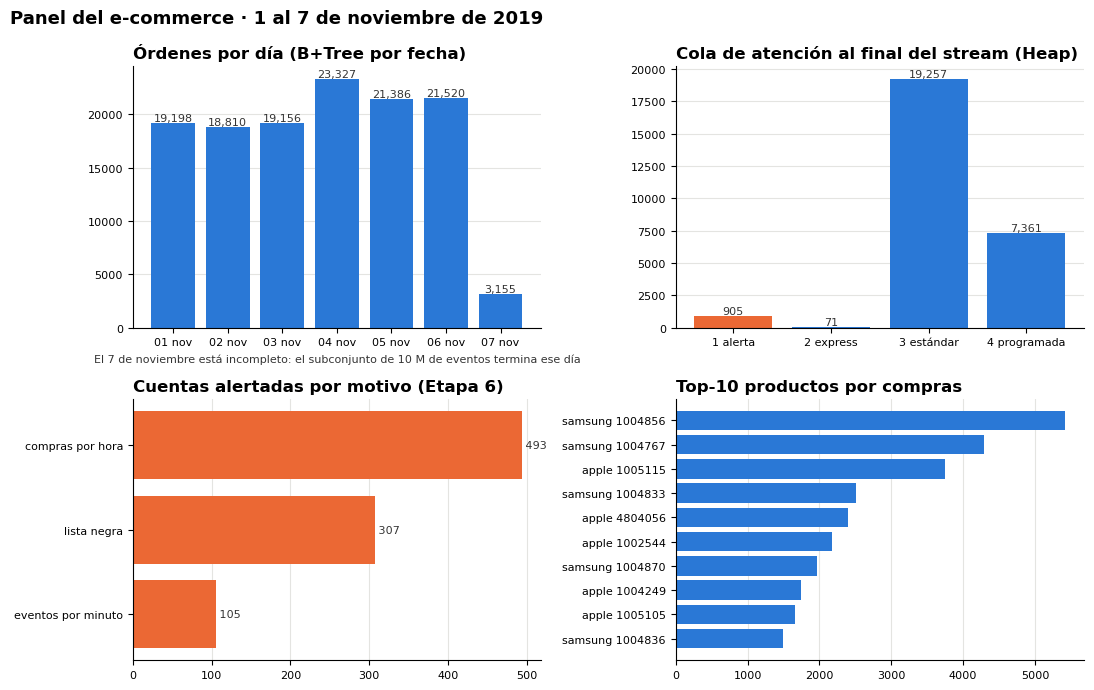

In [62]:
# Panel de ventas, actividad y alertas. Cada gráfico consulta una estructura de las etapas anteriores:
# órdenes por día (B+Tree por fecha, Etapa 4), cola de atención (Heap, Etapas 2 y 6),
# alertas por motivo (Etapa 6) y Top-10 de productos (heap Top-K).
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, REJILLA = "#2a78d6", "#eb6834", "#333333", "#e4e4e1"

dias = pd.date_range("2019-11-01", "2019-11-07", tz="UTC")
ordenes_por_dia = [
    len({o for conjunto in indice_fecha.values(min=int(d.timestamp()), max=int(d.timestamp()) + 86_399) for o in conjunto})
    for d in dias
]
cola = pd.Series([e[0] for e in cola_prioridad]).value_counts().sort_index()
nombres_prioridad = {1: "1 alerta", 2: "2 express", 3: "3 estándar", 4: "4 programada"}

fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
ax = ejes[0, 0]
ax.bar([d.strftime("%d nov") for d in dias], ordenes_por_dia, color=AZUL)
ax.set_title("Órdenes por día (B+Tree por fecha)", loc="left", fontweight="bold")
ax.set_xlabel("El 7 de noviembre está incompleto: el subconjunto de 10 M de eventos termina ese día", fontsize=8, color=TINTA)
for x, v in enumerate(ordenes_por_dia):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=TINTA)

ax = ejes[0, 1]
ax.bar([nombres_prioridad.get(p, str(p)) for p in cola.index], cola.values, color=[NARANJA if p == 1 else AZUL for p in cola.index])
ax.set_title("Cola de atención al final del stream (Heap)", loc="left", fontweight="bold")
for x, v in enumerate(cola.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=TINTA)

ax = ejes[1, 0]
ax.barh(motivos_alerta.index[::-1], motivos_alerta.values[::-1], color=NARANJA)
ax.set_title("Cuentas alertadas por motivo (Etapa 6)", loc="left", fontweight="bold")
for y, v in enumerate(motivos_alerta.values[::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=TINTA)

ax = ejes[1, 1]
marca = lambda p: tabla_productos[p]["marca"] if isinstance(tabla_productos[p]["marca"], str) else "sin marca"
etiquetas = [f"{marca(p)} {p}" for _, p in top_compras][::-1]
ax.barh(etiquetas, [c for c, _ in top_compras][::-1], color=AZUL)
ax.set_title("Top-10 productos por compras", loc="left", fontweight="bold")

for ax in ejes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x" if ax in (ejes[1, 0], ejes[1, 1]) else "y", color=REJILLA)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8)

fig.suptitle("Panel del e-commerce · 1 al 7 de noviembre de 2019", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("salidas/panel_etapa9.png", dpi=150)
plt.show()

### 9.6 Recorrido de un evento de punta a punta

In [63]:
# Recorrido de punta a punta: una compra real del producto consultado en la Etapa 3,
# hecha por una cuenta sin alerta y cuya orden fue despachada por el Heap.
posicion_despacho = {orden: i + 1 for i, (_, _, orden, _) in enumerate(ordenes_despachadas)}
compra = compras_filtradas[(compras_filtradas["product_id"] == producto_buscar) &
                           compras_filtradas["order_id"].isin(posicion_despacho.keys())].iloc[0]
cuenta, orden, event_id = int(compra["user_id"]), compra["order_id"], int(compra["event_id"])
prioridad, tipo_orden = next((p, t) for p, _, o, t in ordenes_despachadas if o == orden)
datos, origen = consultar_producto(producto_buscar)
segundo = int(pd.Timestamp(compra["event_time"]).timestamp())
fila_usuario_matriz = posicion_usuario.get_loc(cuenta)
_, recomendaciones_cuenta = recomendar(cuenta)

print(f"Evento {event_id}: la cuenta {cuenta} compra el producto {producto_buscar} ({compra['event_time']})\n")
print(f"Etapa 0 | entra a la cola FIFO y sale en el lote {(event_id - 1) // TAMANO_LOTE + 1:,} hacia la Etapa 1")
print(f"Etapa 1 | pasa la validación y no es duplicado: está entre los {registros_limpios:,} eventos limpios")
print(f"Etapa 2 | orden {orden} ({tipo_orden}) con prioridad {prioridad}: despachada en el puesto {posicion_despacho[orden]:,} de {len(ordenes_despachadas):,}")
print(f"Etapa 3 | consulta del producto en O(1) ({origen}): {datos['categoria']}, {datos['marca']}, precio {datos['precio']}, stock {datos['stock']}")
print(f"Etapa 4 | el B+Tree por precio lo encuentra en el rango 100-300: {producto_buscar in productos_rango} | "
      f"órdenes en el mismo segundo según el B+Tree por fecha: {len(indice_fecha.get(segundo, set()))}")
print(f"Etapa 5 | sus 3 productos más parecidos (KD-Tree): {resultado_kdtree['product_id'].tolist()[:3]}")
print(f"Etapa 6 | Bloom Filter: ¿posiblemente en la lista negra? {bool(bloom_lista_negra.contiene([cuenta])[0])} | "
      f"alerta: {usuarios_alertados.get(cuenta, 'ninguna')}")
print(f"Etapa 7 | usuarios parecidos (LSH): {len(similares_lsh(fila_lsh[fila_usuario_matriz])[0]) if fila_usuario_matriz in fila_lsh else 'sin índice (1 producto)'} | "
      f"productos relacionados (HNSW): {relacionados[:3]}")
print(f"Etapa 8 | PageRank del producto: puesto {sorted(pagerank_productos, key=pagerank_productos.get, reverse=True).index(producto_buscar) + 1} de "
      f"{len(pagerank_productos):,} | comunidad Louvain de {sum(1 for c in producto_comunidad.values() if c == producto_comunidad[producto_buscar])} productos")
print(f"Etapa 9 | puesto en el Top-{K_TOP} por compras: {[p for _, p in top_compras].index(producto_buscar) + 1 if producto_buscar in [p for _, p in top_compras] else 'fuera'} | "
      f"recomendaciones para la cuenta: {recomendaciones_cuenta['product_id'].tolist()}")

Evento 712: la cuenta 562958505 compra el producto 1004856 (2019-11-01 00:04:51+00:00)

Etapa 0 | entra a la cola FIFO y sale en el lote 1 hacia la Etapa 1
Etapa 1 | pasa la validación y no es duplicado: está entre los 9,988,997 eventos limpios
Etapa 2 | orden ORD-00000003 (express) con prioridad 2: despachada en el puesto 2 de 99,853
Etapa 3 | consulta del producto en O(1) (CACHÉ): electronics.smartphone, samsung, precio 131.66, stock 542
Etapa 4 | el B+Tree por precio lo encuentra en el rango 100-300: True | órdenes en el mismo segundo según el B+Tree por fecha: 1
Etapa 5 | sus 3 productos más parecidos (KD-Tree): [1004767, 1005115, 4804056]
Etapa 6 | Bloom Filter: ¿posiblemente en la lista negra? False | alerta: ninguna
Etapa 7 | usuarios parecidos (LSH): 1479 | productos relacionados (HNSW): [1004833, 1005100, 1004838]
Etapa 8 | PageRank del producto: puesto 1 de 17,933 | comunidad Louvain de 537 productos
Etapa 9 | puesto en el Top-10 por compras: 1 | recomendaciones para la cuent

### 9.7 Resumen de las Etapas 6 a 9

In [64]:
# Resumen de las Etapas 6 a 9, calculado con los resultados de las celdas anteriores (sin valores escritos a mano).
louvain, lpa = filas_comunidades
resumen = pd.DataFrame([
    {"Etapa": 6, "Estructura": "Bloom Filter (lista negra)", "Resultado": f"falsos positivos {tasa_fp_bloom:.2%} (objetivo 1%); {bloom_lista_negra.bits.nbytes} bytes"},
    {"Etapa": 6, "Estructura": "Count-Min Sketch por ventana", "Resultado": f"{len(usuarios_alertados):,} cuentas alertadas; precisión {precision_alertas:.1%} y recall {recall_alertas:.1%} frente a la etiqueta"},
    {"Etapa": 7, "Estructura": "MinHash + LSH", "Resultado": f"recall {recall_lsh:.1%}; {t_exacto / t_lsh:.0f} veces más rápido que Jaccard exacto"},
    {"Etapa": 7, "Estructura": "HNSW (64 dimensiones, efSearch 80)", "Resultado": f"recall@10 {recall_hnsw:.3f}; {t_bruta_emb / t_hnsw_80:.1f} veces más rápido que la fuerza bruta"},
    {"Etapa": 8, "Estructura": "PageRank", "Resultado": f"Top-10 coincide en {len(set(top_pagerank) & set(top_grado))} de 10 con el grado; Spearman {correlacion:.2f}"},
    {"Etapa": 8, "Estructura": "Louvain vs. Label Propagation", "Resultado": f"modularidad {louvain['Modularidad']} vs. {lpa['Modularidad']}"},
    {"Etapa": 9, "Estructura": "Trie", "Resultado": f"autocompletado {t_lin / t_trie:.0f} veces más rápido que el recorrido lineal"},
    {"Etapa": 9, "Estructura": "Top-K con heap", "Resultado": f"{t_orden / t_heap:.1f} veces más rápido que ordenar todo el catálogo"},
])
pd.set_option("display.max_colwidth", 120)
display(resumen)

,Etapa,Estructura,Resultado
0,6,Bloom Filter (lista negra),falsos positivos 0.98% (objetivo 1%); 368 bytes
1,6,Count-Min Sketch por ventana,905 cuentas alertadas; precisión 100.0% y recall 93.0% frente a la etiqueta
2,7,MinHash + LSH,recall 99.4%; 9 veces más rápido que Jaccard exacto
3,7,"HNSW (64 dimensiones, efSearch 80)",recall@10 1.000; 7.0 veces más rápido que la fuerza bruta
4,8,PageRank,Top-10 coincide en 9 de 10 con el grado; Spearman 0.39
5,8,Louvain vs. Label Propagation,modularidad 0.6538 ± 0.0018 vs. 0.5459 ± 0.0404
6,9,Trie,autocompletado 782 veces más rápido que el recorrido lineal
7,9,Top-K con heap,12.8 veces más rápido que ordenar todo el catálogo
